# MC-STGAT-IDS — Phase 2: Pure MoCo Self-Supervised Pretraining

Parallel to `ssl_byol_final.ipynb`. Same encoder architecture, same config,
same evaluation protocol. The only difference is the SSL objective:
BYOL (predictive with EMA target) vs MoCo (contrastive with queue).

**Purpose**: MoCo serves as the ablation for the SSL objective in the thesis.
All other variables (encoder, augmentation, threshold rule, splits) are held
fixed so the comparison isolates the objective.

In [1]:
import os
os.environ.setdefault('PYTORCH_CUDA_ALLOC_CONF', 'expandable_segments:True')
import gc, json, math, pickle, contextlib, warnings, time, random, copy, hashlib
from collections import Counter, defaultdict
from torch.utils.data import WeightedRandomSampler
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.data import DataLoader, Batch
from torch_geometric.nn import GATConv, GlobalAttention
from torch.cuda.amp import GradScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (f1_score, silhouette_score, roc_auc_score,
                             average_precision_score, confusion_matrix,
                             precision_recall_curve, roc_curve)
from sklearn.preprocessing import StandardScaler
from tqdm import tqdm

if torch.cuda.is_available():
    torch.backends.cudnn.benchmark        = True
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32       = True
torch.set_float32_matmul_precision('high')
warnings.filterwarnings('ignore')
print('Imports ready.')

Imports ready.


In [2]:
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
DATASETS_TO_RUN = ['gotham', 'nf_bot', 'nf_ton']

# ---------- architecture (identical to BYOL) ----------
HIDDEN_DIM     = 128
NUM_HEADS      = 4
NUM_LAYERS     = 3
PROJECTION_DIM = 64

# ---------- MoCo-specific ----------
QUEUE_SIZE  = 4096
TEMPERATURE = 0.10
MOMENTUM    = 0.999

# ---------- objective ----------
USE_MASKED_RECON = False    # match BYOL: clean objective for fair ablation

# ---------- preprocessing ----------
MAX_NODES = 128
MAX_EDGES = 20000
MAX_EDGES_SSL = {'gotham': 2000, 'nf_ton': 10000, 'nf_bot': 15000}

# ---------- structural augmentation (per-dataset, matched to BYOL) ----------
EDGE_DROPOUT_MAP = {'gotham': 0.05, 'nf_ton': 0.05, 'nf_bot': 0.05}
NODE_DROP_MAP    = {'gotham': 0.05, 'nf_ton': 0.05, 'nf_bot': 0.05}
SUBGRAPH_MAP     = {'gotham': 0.85, 'nf_ton': 0.85, 'nf_bot': 0.85}

# ---------- feature augmentation (per-dataset) ----------
FEATURE_MASK_MAP      = {'gotham': 0.25, 'nf_ton': 0.25, 'nf_bot': 0.25}
EDGE_FEATURE_MASK_MAP = {'gotham': 0.05, 'nf_ton': 0.05, 'nf_bot': 0.05}

# ---------- batch size (per-dataset) ----------
BATCH_SIZE_MAP = {'gotham': 128, 'nf_bot': 128, 'nf_ton': 128}

# ---------- balanced sampler (nf_bot only) ----------
USE_BALANCED_SAMPLER = {'gotham': False, 'nf_bot': True, 'nf_ton': False}

# ---------- optimisation ----------
BASE_LR = 3e-4
BASE_BS = 128
def scaled_lr(bs): return BASE_LR * math.sqrt(bs / BASE_BS)
GRAD_ACCUM_STEPS = 1
WEIGHT_DECAY     = 1e-3
EPOCHS           = 100
EVAL_INTERVAL    = 5
PATIENCE         = 10
WARMUP_EPOCHS    = 10
MIN_LR_FRAC      = 1e-2

# ---------- collapse detection ----------
COLLAPSE_COS_THRESHOLD = 0.85
COLLAPSE_CONSEC_EVALS  = 3

# ---------- misc ----------
KNN_K           = 10
SEED            = 42
PROBE_TRAIN_MAX = 4000
NUM_WORKERS     = 0
PREFETCH_FACTOR = 2

torch.manual_seed(SEED); np.random.seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)

print(f'Device: {DEVICE}')
print(f'  MAX_EDGES_SSL       = {MAX_EDGES_SSL}')
print(f'  BATCH_SIZE_MAP      = {BATCH_SIZE_MAP}')
print(f'  USE_BALANCED_SAMPLER= {USE_BALANCED_SAMPLER}')
print(f'  EDGE_DROPOUT_MAP    = {EDGE_DROPOUT_MAP}')
print(f'  FEATURE_MASK_MAP    = {FEATURE_MASK_MAP}')
print(f'  USE_MASKED_RECON    = {USE_MASKED_RECON}')
print(f'  QUEUE_SIZE={QUEUE_SIZE}  TEMPERATURE={TEMPERATURE}  MOMENTUM={MOMENTUM}')

Device: cuda
  MAX_EDGES_SSL       = {'gotham': 2000, 'nf_ton': 10000, 'nf_bot': 15000}
  BATCH_SIZE_MAP      = {'gotham': 128, 'nf_bot': 128, 'nf_ton': 128}
  USE_BALANCED_SAMPLER= {'gotham': False, 'nf_bot': True, 'nf_ton': False}
  EDGE_DROPOUT_MAP    = {'gotham': 0.05, 'nf_ton': 0.05, 'nf_bot': 0.05}
  FEATURE_MASK_MAP    = {'gotham': 0.25, 'nf_ton': 0.25, 'nf_bot': 0.25}
  USE_MASKED_RECON    = False
  QUEUE_SIZE=4096  TEMPERATURE=0.1  MOMENTUM=0.999


In [3]:
def gotham_family_merger(lbl):
    if lbl.startswith('Merlin'): return 'Merlin'
    if lbl.startswith('Mirai'):  return 'Mirai'
    return lbl

DATASET_CONFIG = {
    'gotham': {
        'dir': 'Gotham_processed_features_10s/graphs',
        'attack_threshold': 0,
        'label_merge_fn': gotham_family_merger,
    },
    'nf_ton': {
        'dir': 'NFToNIoT_v3_10s/graphs',
        'attack_threshold': 0,
        'label_merge_fn': None,
    },
    'nf_bot': {
        'dir': 'NFBoTIoT_v3_10s/graphs',
        'attack_threshold': 0,
        'label_merge_fn': None,
    },
}

for k, v in DATASET_CONFIG.items():
    print(f"  {k:<8}  thresh={v['attack_threshold']}  "
          f"merge={'yes' if v['label_merge_fn'] else 'no'}")

  gotham    thresh=0  merge=yes
  nf_ton    thresh=0  merge=no
  nf_bot    thresh=0  merge=no


In [4]:
if DEVICE.type == 'cuda':
    try:
        from torch.amp import autocast as _ac
        def autocast_ctx(): return _ac(device_type='cuda', dtype=torch.float16)
    except Exception:
        from torch.cuda.amp import autocast as _ac
        def autocast_ctx(): return _ac(enabled=True)
else:
    def autocast_ctx(): return contextlib.nullcontext()

In [5]:
def cap_graph(g, max_nodes=None, max_edges=None):
    max_nodes = MAX_NODES if max_nodes is None else max_nodes
    max_edges = MAX_EDGES if max_edges is None else max_edges
    g = g.clone(); num_nodes = g.num_nodes
    if g.edge_index.size(1) > max_edges:
        keep = torch.randperm(g.edge_index.size(1))[:max_edges]
        g.edge_index = g.edge_index[:, keep]
        if g.edge_attr is not None and g.edge_attr.size(0) > 0:
            if g.edge_attr.dim() > 2:
                g.edge_attr = g.edge_attr.view(-1, g.edge_attr.size(-1))
            g.edge_attr = g.edge_attr[keep]
    if num_nodes > max_nodes:
        deg = torch.zeros(num_nodes, dtype=torch.long)
        deg.scatter_add_(0, g.edge_index[0],
                         torch.ones(g.edge_index.size(1), dtype=torch.long))
        kn = torch.topk(deg, max_nodes).indices
        mask = torch.zeros(num_nodes, dtype=torch.bool); mask[kn] = True
        s, d = g.edge_index; keep_e = mask[s] & mask[d]
        g.edge_index = g.edge_index[:, keep_e]
        if g.edge_attr is not None and g.edge_attr.size(0) > 0:
            g.edge_attr = g.edge_attr[keep_e]
        remap = torch.zeros(num_nodes, dtype=torch.long)
        remap[mask] = torch.arange(max_nodes, dtype=torch.long)
        g.edge_index = remap[g.edge_index]; g.x = g.x[mask]
    return g

def cap_edges_only(g, max_edges):
    if g.edge_index.size(1) <= max_edges:
        return g
    g = g.clone()
    keep = torch.randperm(g.edge_index.size(1))[:max_edges]
    g.edge_index = g.edge_index[:, keep]
    if g.edge_attr is not None and g.edge_attr.size(0) > 0:
        g.edge_attr = g.edge_attr[keep]
    return g

def dominant_family(g, attack_threshold=0.10, label_merge_fn=None,
                    blacklist=('Unknown', 'unknown', 'UNKNOWN')):
    names = getattr(g, 'edge_attack_names', None)
    if not names:
        lbl = 'Benign'
    else:
        c = Counter(names); total = sum(c.values())
        atk = {k: v for k, v in c.items() if k != 'Benign' and k not in blacklist}
        if not atk or sum(atk.values()) / max(total, 1) < attack_threshold:
            lbl = 'Benign'
        else:
            lbl = max(atk, key=atk.get)
    if label_merge_fn is not None:
        lbl = label_merge_fn(lbl)
    return lbl

def size_aware_rate(num_edges, base_rate):
    if num_edges < 500:  return base_rate * 0.4
    if num_edges < 2000: return base_rate * 0.7
    return base_rate

def _rate_vec(edge_counts, base_rate):
    c = edge_counts.to(torch.float32)
    r = torch.full_like(c, base_rate)
    r = torch.where(c < 2000, c.new_full((), base_rate * 0.7), r)
    r = torch.where(c < 500,  c.new_full((), base_rate * 0.4), r)
    return r

@torch.no_grad()
def augment_batch(batch, edge_drop, feat_mask, node_drop, subgraph,
                  edge_feat_mask=None, want_clean_b1=False):
    if edge_feat_mask is None:
        edge_feat_mask = feat_mask
    num_edges = batch.edge_index.size(1)
    device    = batch.edge_index.device
    num_nodes = batch.x.size(0)
    if edge_drop > 0.0 and num_edges > 0:
        edge_graph  = batch.batch[batch.edge_index[0]]
        edge_counts = torch.bincount(edge_graph, minlength=batch.num_graphs)
        edge_rates  = _rate_vec(edge_counts, edge_drop)[edge_graph]
    else:
        edge_rates = None
    eff_feat      = size_aware_rate(num_edges, feat_mask)      if feat_mask > 0.0 else 0.0
    eff_edge_feat = size_aware_rate(num_edges, edge_feat_mask) if edge_feat_mask > 0.0 else 0.0
    do_node       = (node_drop > 0.0) or (subgraph < 1.0)

    def _one(b, save_clean=False):
        clean_x = None
        if edge_rates is not None and b.edge_index.size(1) > 0:
            keep = torch.rand(b.edge_index.size(1), device=device) >= edge_rates
            b.edge_index = b.edge_index[:, keep]
            if b.edge_attr is not None:
                b.edge_attr = b.edge_attr[keep]
        if do_node:
            keep_p    = max(0.0, (1.0 - node_drop) * subgraph)
            node_keep = torch.rand(num_nodes, device=device) < keep_p
            if b.num_graphs > 1 or not bool(node_keep.any()):
                kept_per_graph = torch.bincount(
                    b.batch[node_keep], minlength=b.num_graphs)
                empty = (kept_per_graph == 0).nonzero(as_tuple=False).squeeze(1)
                if empty.numel() > 0:
                    first_idx = torch.full((b.num_graphs,), num_nodes,
                                           dtype=torch.long, device=device)
                    idx = torch.arange(num_nodes, device=device)
                    first_idx.scatter_reduce_(0, b.batch, idx,
                                              reduce='amin', include_self=True)
                    pick = (idx == first_idx[b.batch]) & (kept_per_graph[b.batch] == 0)
                    node_keep |= pick
            s, d  = b.edge_index
            ekeep = node_keep[s] & node_keep[d]
            b.edge_index = b.edge_index[:, ekeep]
            if b.edge_attr is not None and b.edge_attr.numel() > 0:
                b.edge_attr = b.edge_attr[ekeep]
            b.x     = b.x[node_keep]
            b.batch = b.batch[node_keep]
            remap = torch.full((num_nodes,), -1, dtype=torch.long, device=device)
            n_keep = int(node_keep.sum())
            remap[node_keep] = torch.arange(n_keep, device=device)
            if b.edge_index.numel() > 0:
                b.edge_index = remap[b.edge_index]
        if save_clean:
            clean_x = b.x.clone()
        if eff_feat > 0.0:
            b.x.masked_fill_(torch.rand(b.x.shape, device=device) < eff_feat, 0.0)
        if eff_edge_feat > 0.0 and b.edge_attr is not None and b.edge_attr.numel() > 0:
            b.edge_attr.masked_fill_(
                torch.rand(b.edge_attr.shape, device=device) < eff_edge_feat, 0.0)
        if b.x.size(0) == 0:
            b.x = torch.zeros(1, batch.x.size(1),
                              device=device, dtype=batch.x.dtype)
            b.batch = torch.zeros(1, dtype=torch.long, device=device)
        if b.edge_index.size(1) == 0:
            b.edge_index = torch.empty(2, 0, device=device, dtype=torch.long)
            if b.edge_attr is not None:
                b.edge_attr = torch.empty(0, b.edge_attr.size(-1),
                                          device=device, dtype=b.edge_attr.dtype)
        return b, clean_x

    if want_clean_b1:
        b2, _        = _one(batch.clone(), save_clean=False)
        b1, clean_x1 = _one(batch,          save_clean=True)
        return b1, b2, clean_x1
    else:
        b2, _ = _one(batch.clone())
        b1, _ = _one(batch)
        return b1, b2

def _collate_graphs_only(batch):
    return Batch.from_data_list(batch)

print('Graph utilities ready.')

Graph utilities ready.


In [6]:
class GATEncoder(nn.Module):
    def __init__(self, in_ch, hid, heads, layers, edge_dim):
        super().__init__()
        self.convs = nn.ModuleList(); self.bns = nn.ModuleList()
        self.convs.append(GATConv(in_ch, hid, heads=heads, edge_dim=edge_dim,
                                  concat=True, dropout=0.0))
        self.bns.append(nn.BatchNorm1d(hid * heads))
        for _ in range(layers - 2):
            self.convs.append(GATConv(hid * heads, hid, heads=heads,
                                      edge_dim=edge_dim, concat=True, dropout=0.0))
            self.bns.append(nn.BatchNorm1d(hid * heads))
        self.convs.append(GATConv(hid * heads, hid, heads=1, edge_dim=edge_dim,
                                  concat=False, dropout=0.0))
        self.bns.append(nn.BatchNorm1d(hid))
        self.edge_dim = edge_dim
        self.pool_gate = nn.Sequential(
            nn.Linear(hid, hid), nn.ReLU(), nn.Linear(hid, 1))

    def forward(self, x, ei, ea=None, b=None, return_nodes=False):
        for i, c in enumerate(self.convs):
            x = c(x, ei, edge_attr=ea) if (ea is not None and self.edge_dim > 0) \
                else c(x, ei)
            x = F.relu(self.bns[i](x))
        h = GlobalAttention(self.pool_gate)(x, b)
        if return_nodes:
            return x, h
        return h


class MoCoModel(nn.Module):
    def __init__(self, in_ch, hid, heads, layers, edge_dim, proj_dim,
                 queue_size=None, temperature=None):
        super().__init__()
        queue_size  = QUEUE_SIZE  if queue_size  is None else queue_size
        temperature = TEMPERATURE if temperature is None else temperature
        self.encoder   = GATEncoder(in_ch, hid, heads, layers, edge_dim)
        self.projector = nn.Sequential(
            nn.Linear(hid, hid), nn.BatchNorm1d(hid), nn.ReLU(),
            nn.Linear(hid, proj_dim))
        self.queue_size  = queue_size
        self.temperature = temperature
        self.register_buffer('queue',        torch.zeros(queue_size, proj_dim))
        self.register_buffer('queue_ptr',    torch.zeros(1, dtype=torch.long))
        self.register_buffer('queue_filled', torch.zeros(1, dtype=torch.long))

    def forward(self, x, ei, ea=None, b=None, return_nodes=False):
        if return_nodes:
            h_nodes, h = self.encoder(x, ei, ea, b, return_nodes=True)
            z = self.projector(h)
            return h_nodes, h, z
        h = self.encoder(x, ei, ea, b)
        z = self.projector(h)
        return h, z

    @torch.no_grad()
    def dequeue_and_enqueue(self, keys):
        keys = keys.detach()
        bs   = keys.shape[0]
        ptr  = int(self.queue_ptr)
        if bs >= self.queue_size:
            self.queue.copy_(keys[-self.queue_size:])
            self.queue_ptr[0]    = 0
            self.queue_filled[0] = self.queue_size
            return
        if ptr + bs <= self.queue_size:
            self.queue[ptr:ptr + bs] = keys
        else:
            first = self.queue_size - ptr
            self.queue[ptr:] = keys[:first]
            self.queue[:bs - first] = keys[first:]
        self.queue_ptr[0] = (ptr + bs) % self.queue_size
        self.queue_filled[0] = min(int(self.queue_filled.item()) + bs,
                                   self.queue_size)


@torch.no_grad()
def update_momentum_encoder(target, online, m):
    t_params = list(target.parameters())
    o_params = list(online.parameters())
    torch._foreach_mul_(t_params, m)
    torch._foreach_add_(t_params, o_params, alpha=1 - m)
    online_bufs = dict(online.named_buffers())
    for name, tb in target.named_buffers():
        ob = online_bufs.get(name, None)
        if ob is None or tb.shape != ob.shape: continue
        if name in ('queue', 'queue_ptr', 'queue_filled'):
            continue
        if not tb.is_floating_point():
            if name.endswith('num_batches_tracked'):
                tb.data.copy_(ob.data)
            continue
        tb.data.mul_(m).add_(ob.data, alpha=1 - m)


def info_nce_loss(q, k_pos, k_neg, temperature, use_queue=True,
                  hard_k=8, hard_mult=2.0):
    l_pos = (q * k_pos).sum(-1, keepdim=True)
    if use_queue and k_neg is not None and k_neg.size(0) > 0:
        l_neg = (q @ k_neg.t()) / temperature
        kk = min(hard_k, l_neg.size(1))
        if kk > 0 and hard_mult != 1.0:
            topk_idx = torch.topk(l_neg, k=kk, dim=1).indices
            weight   = torch.ones_like(l_neg)
            weight.scatter_(1, topk_idx, hard_mult)
            l_neg = l_neg * weight
        logits = torch.cat([l_pos / temperature, l_neg], dim=1)
    else:
        logits = (q @ k_pos.t()) / temperature
    labels = torch.zeros(logits.size(0), dtype=torch.long,
                         device=logits.device)
    return F.cross_entropy(logits, labels)

print('Models + losses ready.')

Models + losses ready.


In [7]:
@torch.inference_mode()
def embed_graphs(encoder, graphs, device, batch_size=64):
    encoder.eval()
    chunks = []; i = 0; cur_bs = batch_size
    while i < len(graphs):
        chunk = graphs[i:i + cur_bs]
        try:
            batch = Batch.from_data_list(chunk).to(device)
            with autocast_ctx():
                out = encoder(batch.x, batch.edge_index,
                              batch.edge_attr, batch.batch)
            if isinstance(out, tuple): out = out[-1]
            arr = out.float().cpu().numpy()
            arr = np.nan_to_num(arr, nan=0.0, posinf=100.0, neginf=-100.0)
            chunks.append(arr)
            del batch, out
            i += cur_bs
            if device.type == 'cuda': torch.cuda.empty_cache()
        except RuntimeError as e:
            if 'out of memory' in str(e).lower() and cur_bs > 1:
                torch.cuda.empty_cache()
                cur_bs = max(1, cur_bs // 2); continue
            raise
    return np.vstack(chunks)

def embedding_stats(X):
    X = np.asarray(X)
    sv = np.linalg.svd(X - X.mean(0), compute_uv=False)
    eff_rank = float((sv**2).sum() / (sv[0]**2)) if sv[0] > 0 else 0.0
    rng = np.random.default_rng(0)
    idx_a = rng.integers(0, len(X), min(500, len(X)))
    idx_b = rng.integers(0, len(X), min(500, len(X)))
    a = X[idx_a]; b = X[idx_b]
    cos = (a * b).sum(1) / (np.linalg.norm(a, axis=1) * np.linalg.norm(b, axis=1) + 1e-8)
    return dict(eff_rank=eff_rank,
                per_dim_std_mean=float(X.std(0).mean()),
                mean_cos_sim=float(np.nanmean(cos)))

def _balanced_accuracy_threshold(prob, y):
    prob = np.asarray(prob); y = np.asarray(y)
    if len(set(y)) < 2: return 0.5, 0.0
    fpr, tpr, thr = roc_curve(y, prob)
    ba = 0.5 * (tpr + (1.0 - fpr))
    idx = int(np.argmax(ba))
    return float(thr[idx]), float(ba[idx])

def _safe_f1(y_true, y_pred, average):
    try: return float(f1_score(y_true, y_pred, average=average, zero_division=0))
    except Exception: return 0.0

def _pr_block(prob_test, y_test_i):
    atk_base = float(y_test_i.mean()); ben_base = 1.0 - atk_base
    out = {}
    try: out['attack_pr_auc'] = float(average_precision_score(y_test_i, prob_test))
    except ValueError: out['attack_pr_auc'] = float('nan')
    out['attack_pr_baseline'] = atk_base
    out['attack_pr_lift']     = out['attack_pr_auc'] - atk_base
    try: out['benign_pr_auc'] = float(
        average_precision_score(1 - y_test_i, 1.0 - prob_test))
    except ValueError: out['benign_pr_auc'] = float('nan')
    out['benign_pr_baseline'] = ben_base
    out['benign_pr_lift']     = out['benign_pr_auc'] - ben_base
    try:
        prec, rec, thr = precision_recall_curve(y_test_i, prob_test)
        prec, rec = prec[:-1], rec[:-1]
        mask = rec >= 0.95
        if mask.any():
            idxs = np.where(mask)[0]
            best = idxs[int(np.argmax(prec[mask]))]
            out['attack_precision_at_r95'] = float(prec[best])
            out['attack_recall_at_r95']    = float(rec[best])
            out['attack_thr_at_r95']       = float(thr[best])
        else:
            for k in ['attack_precision_at_r95', 'attack_recall_at_r95',
                      'attack_thr_at_r95']:
                out[k] = float('nan')
    except Exception:
        for k in ['attack_precision_at_r95', 'attack_recall_at_r95',
                  'attack_thr_at_r95']:
            out[k] = float('nan')
    return out

def frozen_linear_probe(encoder, X_train, y_train, X_val, y_val,
                        X_test, y_test):
    X_train = np.nan_to_num(X_train, nan=0.0, posinf=100.0, neginf=-100.0)
    X_val   = np.nan_to_num(X_val,   nan=0.0, posinf=100.0, neginf=-100.0)
    X_test  = np.nan_to_num(X_test,  nan=0.0, posinf=100.0, neginf=-100.0)
    scaler = StandardScaler().fit(X_train)
    Xtr = scaler.transform(X_train); Xva = scaler.transform(X_val)
    Xte = scaler.transform(X_test)
    empty = {'val_roc': 0.0, 'test_roc': 0.0, 'test_pr': 0.0,
             'test_f1': 0.0, 'test_f1_binary': 0.0,
             'test_macro_f1': 0.0, 'test_weighted_f1': 0.0,
             'val_macro_f1': 0.0, 'val_weighted_f1': 0.0,
             'test_fpr': 0.0, 'test_fnr': 0.0,
             'threshold': 0.5, 'test_knn_roc': 0.0, 'val_silhouette': 0.0,
             'attack_pr_auc': float('nan'), 'attack_pr_baseline': float('nan'),
             'attack_pr_lift': float('nan'),
             'benign_pr_auc': float('nan'), 'benign_pr_baseline': float('nan'),
             'benign_pr_lift': float('nan'),
             'attack_precision_at_r95': float('nan'),
             'attack_recall_at_r95': float('nan'),
             'attack_thr_at_r95': float('nan')}
    out = {}
    if len(set(y_train)) < 2:
        out.update(empty); return out
    lr = LogisticRegression(max_iter=3000, class_weight='balanced',
                            n_jobs=-1).fit(Xtr, y_train)
    prob_val  = lr.predict_proba(Xva)[:, 1]
    prob_test = lr.predict_proba(Xte)[:, 1]
    # Balanced-accuracy threshold (== Youden's J) — robust default
    thr, _ = _balanced_accuracy_threshold(prob_val, y_val)
    pred_val  = (prob_val  >= thr).astype(int)
    pred_test = (prob_test >= thr).astype(int)
    out['val_roc']  = float(roc_auc_score(y_val, prob_val))
    out['test_roc'] = float(roc_auc_score(y_test, prob_test))
    out['test_pr']  = float(average_precision_score(y_test, prob_test))
    out['test_f1']          = _safe_f1(y_test, pred_test, 'binary')
    out['test_f1_binary']   = out['test_f1']
    out['test_macro_f1']    = _safe_f1(y_test, pred_test, 'macro')
    out['test_weighted_f1'] = _safe_f1(y_test, pred_test, 'weighted')
    out['val_macro_f1']     = _safe_f1(y_val,  pred_val,  'macro')
    out['val_weighted_f1']  = _safe_f1(y_val,  pred_val,  'weighted')
    cm  = confusion_matrix(y_test, pred_test, labels=[0, 1])
    cmn = cm / cm.sum(1, keepdims=True).clip(min=1)
    out['test_fpr'] = float(cmn[0, 1]); out['test_fnr'] = float(cmn[1, 0])
    out['threshold'] = float(thr)
    y_test_i = np.asarray(y_test).astype(int)
    out.update(_pr_block(prob_test, y_test_i))
    try:
        knn = KNeighborsClassifier(n_neighbors=KNN_K, weights='distance',
                                   n_jobs=-1).fit(Xtr, y_train)
        out['test_knn_roc'] = float(roc_auc_score(
            y_test, knn.predict_proba(Xte)[:, 1]))
    except Exception:
        out['test_knn_roc'] = 0.0
    if len(set(y_val)) > 1 and len(X_val) > 3:
        try: out['val_silhouette'] = float(silhouette_score(X_val, y_val, metric='cosine'))
        except Exception: out['val_silhouette'] = 0.0
    else: out['val_silhouette'] = 0.0
    return out

print('Eval helpers ready.')

Eval helpers ready.


In [8]:
BUNDLES = {}

def _split_protocol_hash(norm_stats):
    key = json.dumps({
        'split_protocol': norm_stats.get('split_protocol', 'unknown'),
        'block_size_sec': norm_stats.get('block_size_sec', None),
        'purge_sec':      norm_stats.get('purge_sec', None),
        'attack_threshold': norm_stats.get('attack_threshold_used_for_split', None),
        'label_merge_applied': norm_stats.get('label_merge_applied', None),
    }, sort_keys=True)
    return hashlib.md5(key.encode()).hexdigest()[:12]


def load_dataset_bundle(DATASET_NAME, force_reload=False):
    if (not force_reload) and DATASET_NAME in BUNDLES:
        print(f"[cache] bundle '{DATASET_NAME}' already loaded")
        return BUNDLES[DATASET_NAME]

    cfg = DATASET_CONFIG[DATASET_NAME]
    DATA_DIR = cfg['dir']
    CHECKPOINT_DIR = os.path.join(DATA_DIR, 'ssl_checkpoints_moco')
    os.makedirs(CHECKPOINT_DIR, exist_ok=True)
    report_path  = os.path.join(CHECKPOINT_DIR, 'ssl_report.json')
    encoder_path = os.path.join(CHECKPOINT_DIR, 'ssl_encoder_best.pth')

    attack_threshold = cfg['attack_threshold']
    label_merge_fn   = cfg['label_merge_fn']
    print(f"\nLoading bundle — {DATASET_NAME}")
    print(f"  threshold={attack_threshold}  "
          f"merge={'yes' if label_merge_fn else 'no'}")

    def load_graphs(split):
        with open(os.path.join(DATA_DIR, f'{split}_graphs.pkl'), 'rb') as f:
            return pickle.load(f)

    train_graphs = [cap_graph(g) for g in load_graphs('train')]
    val_graphs   = [cap_graph(g) for g in load_graphs('val')]
    test_graphs  = [cap_graph(g) for g in load_graphs('test')]
    print(f"  loaded train={len(train_graphs)} val={len(val_graphs)} "
          f"test={len(test_graphs)}")

    def is_attack(g):
        return 0 if dominant_family(g, attack_threshold,
                                     label_merge_fn) == 'Benign' else 1

    train_bin = np.array([is_attack(g) for g in train_graphs], dtype=np.int64)
    val_bin   = np.array([is_attack(g) for g in val_graphs],   dtype=np.int64)
    test_bin  = np.array([is_attack(g) for g in test_graphs],  dtype=np.int64)
    print(f"  attack rate: train={train_bin.mean():.3f} "
          f"val={val_bin.mean():.3f} test={test_bin.mean():.3f}")

    with open(os.path.join(DATA_DIR, 'norm_stats.json')) as f:
        ns = json.load(f)
    N_CONT    = ns['n_continuous_edge_feats']
    node_mean = torch.tensor(ns['node_mean'], dtype=torch.float)
    node_std  = torch.tensor(ns['node_std'],  dtype=torch.float)
    edge_mean = torch.tensor(ns['edge_mean'], dtype=torch.float)
    edge_std  = torch.tensor(ns['edge_std'],  dtype=torch.float)

    split_hash = _split_protocol_hash(ns)
    print(f"  split protocol: {ns.get('split_protocol', 'unknown')}  "
          f"(hash={split_hash})")

    if os.path.isfile(encoder_path):
        try:
            old = torch.load(encoder_path, map_location='cpu')
            old_hash = old.get('split_protocol_hash', None)
            if old_hash is not None and old_hash != split_hash:
                print(f"  [STALE] checkpoint split_hash={old_hash} != "
                      f"{split_hash}; removing")
                os.remove(encoder_path)
                if os.path.isfile(report_path): os.remove(report_path)
        except Exception as e:
            print(f"  [warn] could not inspect existing checkpoint: {e}")

    def normalise(graphs):
        for g in graphs:
            g.x = torch.clamp((g.x - node_mean) / (node_std + 1e-8), -10, 10)
            if g.edge_attr is not None and g.edge_attr.size(0) > 0:
                if g.edge_attr.dim() > 2:
                    g.edge_attr = g.edge_attr.view(-1, g.edge_attr.size(-1))
                c, p = g.edge_attr[:, :N_CONT], g.edge_attr[:, N_CONT:]
                c = torch.clamp((c - edge_mean) / (edge_std + 1e-8), -10, 10)
                g.edge_attr = torch.cat([c, p], dim=1)
            if g.edge_attr is None or g.edge_attr.size(0) == 0:
                g.edge_attr = torch.zeros((g.edge_index.size(1), N_CONT),
                                          dtype=torch.float)
            g.x = torch.nan_to_num(g.x, nan=0.0, posinf=0.0, neginf=0.0)
            g.edge_attr = torch.nan_to_num(g.edge_attr, nan=0.0,
                                           posinf=0.0, neginf=0.0)

    normalise(train_graphs); normalise(val_graphs); normalise(test_graphs)

    ssl_graphs = []
    for g in train_graphs:
        gc_ = g.clone()
        for a in ['y', 'edge_y', 'y_multihot', 'attack_label']:
            if hasattr(gc_, a): delattr(gc_, a)
        ssl_graphs.append(gc_)
    cap = MAX_EDGES_SSL.get(DATASET_NAME)
    if cap is not None:
        n_capped = 0
        for i, g in enumerate(ssl_graphs):
            if g.edge_index.size(1) > cap:
                ssl_graphs[i] = cap_edges_only(g, cap)
                n_capped += 1
        pct = 100.0 * n_capped / max(len(ssl_graphs), 1)
        print(f"  [ssl-cap] {n_capped} graphs capped to <= {cap} edges ({pct:.1f}%)")
        if pct > 15.0:
            print(f"  [warn] {pct:.1f}% capped")

    if len(train_graphs) > PROBE_TRAIN_MAX:
        rng_probe = np.random.default_rng(SEED)
        idx = rng_probe.choice(len(train_graphs), PROBE_TRAIN_MAX, replace=False)
        probe_train_graphs = [train_graphs[i] for i in idx]
        probe_train_bin    = train_bin[idx]
    else:
        probe_train_graphs = train_graphs
        probe_train_bin    = train_bin

    inner_val_graphs = val_graphs; inner_val_bin = val_bin
    n_benign_val = int((val_bin == 0).sum())
    if n_benign_val < 200:
        idx_tr, idx_inner = train_test_split(
            np.arange(len(train_graphs)),
            test_size=0.20, random_state=SEED, stratify=train_bin)
        probe_train_graphs = [train_graphs[i] for i in idx_tr]
        probe_train_bin    = train_bin[idx_tr]
        inner_val_graphs   = [train_graphs[i] for i in idx_inner]
        inner_val_bin      = train_bin[idx_inner]
        print(f"  [inner-val] official val has {n_benign_val} benign; "
              f"using inner split (probe_train={len(idx_tr)}, "
              f"inner_val={len(idx_inner)})")

    samp = ssl_graphs[0]
    node_dim = samp.x.size(1); edge_dim = samp.edge_attr.size(1)
    bundle = {
        'name': DATASET_NAME,
        'attack_threshold': attack_threshold,
        'label_merge_fn':   label_merge_fn,
        'split_protocol_hash': split_hash,
        'split_protocol': ns.get('split_protocol', 'unknown'),
        'train_graphs': train_graphs, 'val_graphs': val_graphs,
        'test_graphs': test_graphs,
        'train_bin': train_bin, 'val_bin': val_bin, 'test_bin': test_bin,
        'ssl_graphs': ssl_graphs,
        'probe_train_graphs': probe_train_graphs,
        'probe_train_bin':    probe_train_bin,
        'inner_val_graphs':   inner_val_graphs,
        'inner_val_bin':      inner_val_bin,
        'N_CONT': N_CONT, 'node_dim': node_dim, 'edge_dim': edge_dim,
        'checkpoint_dir': CHECKPOINT_DIR,
        'report_path': report_path, 'encoder_path': encoder_path,
    }
    BUNDLES[DATASET_NAME] = bundle
    print(f"  bundle ready: node_dim={node_dim} edge_dim={edge_dim} "
          f"n_ssl={len(ssl_graphs)}")
    return bundle

print('Bundle loader ready.')

Bundle loader ready.


In [9]:
def build_moco_loader(bundle, num_workers=None, batch_size=None, balanced=None):
    import torch.utils.data as _tud
    if num_workers is None: num_workers = NUM_WORKERS
    if batch_size is None:  batch_size  = BATCH_SIZE_MAP[bundle['name']]
    if balanced is None:    balanced    = USE_BALANCED_SAMPLER[bundle['name']]
    kwargs = dict(batch_size=batch_size, collate_fn=_collate_graphs_only,
                  num_workers=num_workers, pin_memory=(DEVICE.type == 'cuda'),
                  drop_last=True)
    if num_workers > 0:
        kwargs['persistent_workers'] = True
        kwargs['prefetch_factor']    = PREFETCH_FACTOR
    sampler = None
    if balanced:
        try:
            fams = [dominant_family(g, bundle['attack_threshold'],
                                    bundle.get('label_merge_fn', None))
                    for g in bundle['ssl_graphs']]
            binary = ['Benign' if f == 'Benign' else 'Attack' for f in fams]
            counts = Counter(binary)
            w = np.array([1.0 / max(counts[b], 1) for b in binary], dtype=np.float64)
            w_min = w.min(); w = np.clip(w, w_min, 20.0 * w_min)
            sampler = _tud.WeightedRandomSampler(
                weights=torch.tensor(w, dtype=torch.double),
                num_samples=len(w), replacement=True)
            print(f"  SSL sampler: balanced=True  {dict(counts)}")
        except Exception as e:
            print(f"  [warn] sampler failed: {e}"); sampler = None
    def _make(nw, use_sampler):
        k = dict(kwargs); k['num_workers'] = nw
        if nw == 0:
            k.pop('persistent_workers', None); k.pop('prefetch_factor', None)
        if use_sampler and sampler is not None:
            return _tud.DataLoader(bundle['ssl_graphs'], sampler=sampler, **k)
        return _tud.DataLoader(bundle['ssl_graphs'], shuffle=True, **k)
    use_sampler = (sampler is not None)
    try:
        loader = _make(num_workers, use_sampler)
        if num_workers > 0: _ = iter(loader)
    except Exception as e:
        print(f"  [warn] workers={num_workers} failed: {e}; falling back to 0")
        loader = _make(0, use_sampler)
    return loader

print('Loader builder ready.')

Loader builder ready.


In [10]:
def train_moco_pure_ssl(bundle, loader=None, epochs=None, eval_interval=None,
                        warmup_epochs=None, patience=None, force_retrain=False):
    if epochs        is None: epochs        = EPOCHS
    if eval_interval is None: eval_interval = EVAL_INTERVAL
    if warmup_epochs is None: warmup_epochs = WARMUP_EPOCHS
    if patience      is None: patience      = PATIENCE
    DATASET_NAME = bundle['name']
    BATCH_SIZE   = BATCH_SIZE_MAP[DATASET_NAME]
    LR           = scaled_lr(BATCH_SIZE)
    if loader is None: loader = build_moco_loader(bundle)
    report_path  = bundle['report_path']
    encoder_path = bundle['encoder_path']
    if (not force_retrain) and os.path.isfile(report_path) and os.path.isfile(encoder_path):
        print(f"[SKIP] {DATASET_NAME}: existing MoCo artifacts")
        with open(report_path) as f:
            r = json.load(f); r['_skipped'] = True
        return r
    edge_drop      = EDGE_DROPOUT_MAP[DATASET_NAME]
    feat_mask      = FEATURE_MASK_MAP[DATASET_NAME]
    edge_feat_mask = EDGE_FEATURE_MASK_MAP[DATASET_NAME]
    node_drop      = NODE_DROP_MAP[DATASET_NAME]
    subgraph       = SUBGRAPH_MAP[DATASET_NAME]
    node_dim = bundle['node_dim']; edge_dim = bundle['edge_dim']
    online = MoCoModel(node_dim, HIDDEN_DIM, NUM_HEADS, NUM_LAYERS, edge_dim,
                       PROJECTION_DIM, QUEUE_SIZE, TEMPERATURE).to(DEVICE)
    target = copy.deepcopy(online).to(DEVICE)
    for p in target.parameters(): p.requires_grad = False
    params = list(online.parameters())
    optimizer = torch.optim.AdamW(params, lr=LR, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=epochs, eta_min=LR * MIN_LR_FRAC)
    scaler_amp = GradScaler()
    best_roc = -1.0; best_epoch = 0; no_imp = 0; history = []
    collapse_counter = 0

    print(f"\nStarting MoCo — {DATASET_NAME}  bs={BATCH_SIZE}  lr={LR:.2e}  "
          f"epochs={epochs}  warmup={warmup_epochs}  patience={patience}")
    print(f"  balanced={USE_BALANCED_SAMPLER[DATASET_NAME]}  "
          f"max_edges_ssl={MAX_EDGES_SSL[DATASET_NAME]}  "
          f"edge_drop={edge_drop}  feat_mask={feat_mask}")

    for epoch in range(1, epochs + 1):
        online.train(); target.eval()
        loss_acc = torch.zeros((), device=DEVICE)
        nce_acc  = torch.zeros((), device=DEVICE)
        n_batches = 0
        gn = torch.tensor(0.0)
        t0 = time.time()
        optimizer.zero_grad(set_to_none=True)
        pbar = tqdm(loader, desc=f"Epoch {epoch:03d}", leave=False, dynamic_ncols=True)
        for batch_idx, batch in enumerate(pbar):
            batch = batch.to(DEVICE, non_blocking=True)
            b1, b2 = augment_batch(
                batch, edge_drop, feat_mask, node_drop, subgraph,
                edge_feat_mask=edge_feat_mask)
            with autocast_ctx():
                _, z1 = online(b1.x, b1.edge_index, b1.edge_attr, b1.batch)
                with torch.no_grad():
                    _, z2 = target(b2.x, b2.edge_index, b2.edge_attr, b2.batch)
                z1n = F.normalize(z1.float(), dim=-1)
                z2n = F.normalize(z2.float(), dim=-1)
                use_queue = int(online.queue_filled.item()) >= max(1, BATCH_SIZE)
                l_nce = info_nce_loss(z1n, z2n, online.queue,
                                      online.temperature, use_queue=use_queue)
                loss = l_nce
            scaler_amp.scale(loss).backward()
            is_opt_step = ((batch_idx + 1) % GRAD_ACCUM_STEPS == 0) or \
                          ((batch_idx + 1) == len(loader))
            if is_opt_step:
                scaler_amp.unscale_(optimizer)
                gn = torch.nn.utils.clip_grad_norm_(params, max_norm=1.0)
                scaler_amp.step(optimizer); scaler_amp.update()
                optimizer.zero_grad(set_to_none=True)
                update_momentum_encoder(target, online, MOMENTUM)
                with torch.no_grad():
                    _, z_enq = target(b2.x, b2.edge_index, b2.edge_attr, b2.batch)
                    z_enq = F.normalize(z_enq.float(), dim=-1)
                online.dequeue_and_enqueue(z_enq)
            loss_acc = loss_acc + loss.detach()
            nce_acc  = nce_acc  + l_nce.detach()
            n_batches += 1
            n = max(n_batches, 1)
            cur_lr = optimizer.param_groups[0]['lr']
            q_pct  = float(online.queue_filled.item()) / max(online.queue_size, 1)
            pbar.set_postfix({'loss': f"{loss_acc.item()/n:.4f}",
                              'nce':  f"{nce_acc.item()/n:.4f}",
                              'gnorm': f"{float(gn):.3f}",
                              'lr':   f"{cur_lr:.2e}",
                              'q':    f"{q_pct:.2f}"})
            del b1, b2, loss, z1, z2, z1n, z2n, l_nce
            if DEVICE.type == 'cuda' and (batch_idx + 1) % 25 == 0:
                torch.cuda.empty_cache()
        pbar.close()
        n_batches = max(n_batches, 1)
        total_loss = loss_acc.item() / n_batches
        total_nce  = nce_acc.item()  / n_batches
        scheduler.step()
        epoch_time = time.time() - t0
        current_lr = optimizer.param_groups[0]['lr']

        if epoch % eval_interval == 0 or epoch == 1:
            # NOTE: test set is deliberately NOT embedded here.
            X_train = embed_graphs(online.encoder, bundle['probe_train_graphs'], DEVICE)
            X_val   = embed_graphs(online.encoder, bundle['inner_val_graphs'],   DEVICE)
            stats   = embedding_stats(X_val)
            res = frozen_linear_probe(
                online.encoder,
                X_train, bundle['probe_train_bin'],
                X_val,   bundle['inner_val_bin'],
                X_val,   bundle['inner_val_bin'])
            is_collapsed = stats['mean_cos_sim'] > COLLAPSE_COS_THRESHOLD
            collapse_counter = collapse_counter + 1 if is_collapsed else 0
            collapse_flag = f"  [COLLAPSE?{collapse_counter}]" if is_collapsed else ''
            warmed_up = epoch >= warmup_epochs
            improved  = warmed_up and (res['val_roc'] > best_roc + 1e-4)
            if improved:
                best_roc = res['val_roc']; best_epoch = epoch
                torch.save({
                    'encoder_state_dict': online.encoder.state_dict(),
                    'node_dim': node_dim, 'edge_dim': edge_dim,
                    'hidden_dim': HIDDEN_DIM, 'num_heads': NUM_HEADS,
                    'num_layers': NUM_LAYERS,
                    'n_cont': bundle['N_CONT'], 'max_nodes': MAX_NODES,
                    'max_edges': MAX_EDGES,
                    'max_edges_ssl': MAX_EDGES_SSL.get(DATASET_NAME),
                    'projection_dim': PROJECTION_DIM,
                    'queue_size': QUEUE_SIZE, 'temperature': TEMPERATURE,
                    'momentum': MOMENTUM,
                    'epoch': epoch, 'val_roc_auc': float(res['val_roc']),
                    'ssl_objective': 'pure_moco',
                    'dataset': DATASET_NAME, 'window_sec': 10,
                    'attack_threshold': bundle['attack_threshold'],
                    'label_merge_applied': bundle['label_merge_fn'] is not None,
                    'split_protocol': bundle['split_protocol'],
                    'split_protocol_hash': bundle['split_protocol_hash'],
                    'feature_mask': feat_mask,
                    'edge_feature_mask': edge_feat_mask,
                    'edge_drop': edge_drop, 'node_drop': node_drop,
                    'subgraph': subgraph,
                    'threshold_rule': 'balanced_accuracy',
                }, encoder_path)
                no_imp = 0
            else:
                if warmed_up: no_imp += 1
            pat_left = max(patience - no_imp, 0)
            note = "* best" if improved else ("(warmup)" if not warmed_up else "")
            print(f"Epoch {epoch:03d} | {epoch_time:5.1f}s | lr {current_lr:.2e} | "
                  f"nce {total_nce:.4f} | "
                  f"val ROC {res['val_roc']:.4f} | "
                  f"val macroF1 {res['val_macro_f1']:.4f} | "
                  f"eff_rank {stats['eff_rank']:.2f} cos {stats['mean_cos_sim']:.3f} | "
                  f"pat {pat_left}{collapse_flag}  {note}")
            history.append({'epoch': epoch, 'train_loss': total_loss,
                            'nce': total_nce,
                            'lr': float(current_lr),
                            'eff_rank': stats['eff_rank'],
                            'mean_cos_sim': stats['mean_cos_sim'],
                            **{f'probe_{k}': v for k, v in res.items()}})
            if collapse_counter >= COLLAPSE_CONSEC_EVALS:
                print(f"\n[ABORT] encoder collapsed for "
                      f"{COLLAPSE_CONSEC_EVALS} consecutive evals.")
                break
            if warmed_up and no_imp >= patience:
                print(f"\nEarly stopping at epoch {epoch}")
                break
        else:
            print(f"Epoch {epoch:03d} | {epoch_time:5.1f}s | lr {current_lr:.2e} | "
                  f"loss {total_loss:.4f} | nce {total_nce:.4f}")
        gc.collect()
        if DEVICE.type == 'cuda': torch.cuda.empty_cache()

    if not os.path.isfile(encoder_path):
        print("[warn] no best checkpoint; writing last-epoch encoder")
        torch.save({'encoder_state_dict': online.encoder.state_dict(),
                    'node_dim': node_dim, 'edge_dim': edge_dim,
                    'hidden_dim': HIDDEN_DIM, 'num_heads': NUM_HEADS,
                    'num_layers': NUM_LAYERS, 'n_cont': bundle['N_CONT'],
                    'projection_dim': PROJECTION_DIM,
                    'queue_size': QUEUE_SIZE, 'temperature': TEMPERATURE,
                    'momentum': MOMENTUM,
                    'epoch': epochs, 'val_roc_auc': float('nan'),
                    'ssl_objective': 'pure_moco',
                    'dataset': DATASET_NAME, 'window_sec': 10,
                    'attack_threshold': bundle['attack_threshold'],
                    'split_protocol': bundle['split_protocol'],
                    'split_protocol_hash': bundle['split_protocol_hash']},
                    encoder_path)

    ckpt = torch.load(encoder_path, map_location='cpu')
    train_report = {
        'dataset': DATASET_NAME, 'window_sec': 10,
        'ssl_objective': 'pure_moco',
        'ssl_purity': 'labels_never_used_during_pretraining',
        'attack_threshold': bundle['attack_threshold'],
        'label_merge_applied': bundle['label_merge_fn'] is not None,
        'split_protocol': bundle['split_protocol'],
        'split_protocol_hash': bundle['split_protocol_hash'],
        'best_epoch': ckpt['epoch'],
        'best_val_roc': float(ckpt.get('val_roc_auc', float('nan'))),
        'n_train_pool': len(bundle['ssl_graphs']),
        'n_val': len(bundle['inner_val_graphs']),
        'n_test': len(bundle['test_graphs']),
        'history': history,
        'config': {'hidden_dim': HIDDEN_DIM, 'num_heads': NUM_HEADS,
                   'num_layers': NUM_LAYERS,
                   'projection_dim': PROJECTION_DIM,
                   'queue_size': QUEUE_SIZE, 'temperature': TEMPERATURE,
                   'momentum': MOMENTUM,
                   'batch_size': BATCH_SIZE, 'lr': LR, 'epochs': epochs,
                   'weight_decay': WEIGHT_DECAY,
                   'warmup_epochs': warmup_epochs, 'patience': patience,
                   'eval_interval': eval_interval,
                   'use_masked_recon': USE_MASKED_RECON,
                   'max_edges_ssl': MAX_EDGES_SSL.get(DATASET_NAME),
                   'edge_dropout': edge_drop, 'feat_mask': feat_mask,
                   'edge_feat_mask': edge_feat_mask,
                   'node_drop': node_drop, 'subgraph': subgraph,
                   'balanced_sampler': USE_BALANCED_SAMPLER[DATASET_NAME],
                   'labels_used_in_ssl': False,
                   'threshold_rule': 'balanced_accuracy',
                   'collapse_detection_cos': COLLAPSE_COS_THRESHOLD,
                   'collapse_detection_consec': COLLAPSE_CONSEC_EVALS,
                   'seed': SEED}}
    del online, target, optimizer, scheduler, scaler_amp
    gc.collect()
    if DEVICE.type == 'cuda': torch.cuda.empty_cache()
    return train_report

print('Training loop ready.')

Training loop ready.


In [11]:
def final_eval_moco_pure(bundle, save_report=True):
    encoder_path = bundle['encoder_path']
    report_path  = bundle['report_path']
    DATASET_NAME = bundle['name']
    if not os.path.isfile(encoder_path):
        raise FileNotFoundError(f"No checkpoint at {encoder_path}")
    ckpt = torch.load(encoder_path, map_location=DEVICE)
    enc = GATEncoder(ckpt['node_dim'], ckpt['hidden_dim'], ckpt['num_heads'],
                     ckpt['num_layers'], ckpt['edge_dim']).to(DEVICE)
    enc.load_state_dict(ckpt['encoder_state_dict']); enc.eval()
    X_train = embed_graphs(enc, bundle['train_graphs'], DEVICE)
    X_val   = embed_graphs(enc, bundle['val_graphs'],   DEVICE)
    X_test  = embed_graphs(enc, bundle['test_graphs'],  DEVICE)
    res = frozen_linear_probe(enc, X_train, bundle['train_bin'],
                              X_val, bundle['val_bin'],
                              X_test, bundle['test_bin'])
    stats = embedding_stats(X_test)
    print(f"\nFINAL MoCo — {DATASET_NAME}")
    print(f"  val ROC {res['val_roc']:.4f} | test ROC {res['test_roc']:.4f}")
    print(f"  FPR {res['test_fpr']:.4f} | FNR {res['test_fnr']:.4f} | "
          f"silhouette {res['val_silhouette']:.4f}")
    print(f"  binary F1 {res['test_f1_binary']:.4f} | "
          f"macro F1 {res['test_macro_f1']:.4f} | PR-AUC {res['test_pr']:.4f}")
    print(f"  threshold {res['threshold']:.4f}")
    print(f"  eff_rank {stats['eff_rank']:.2f} | "
          f"mean_cos_sim {stats['mean_cos_sim']:.3f}")
    if stats['mean_cos_sim'] > COLLAPSE_COS_THRESHOLD:
        print(f"  [WARN] encoder may be collapsed")
    eval_report = {
        'optimal_threshold': float(res['threshold']),
        'val_roc_auc': float(res['val_roc']),
        'test_roc_auc': float(res['test_roc']),
        'test_pr_auc': float(res['test_pr']),
        'attack_pr_auc': float(res['attack_pr_auc']),
        'attack_pr_baseline': float(res['attack_pr_baseline']),
        'attack_pr_lift': float(res['attack_pr_lift']),
        'benign_pr_auc': float(res['benign_pr_auc']),
        'benign_pr_baseline': float(res['benign_pr_baseline']),
        'benign_pr_lift': float(res['benign_pr_lift']),
        'attack_precision_at_r95': float(res['attack_precision_at_r95']),
        'attack_recall_at_r95': float(res['attack_recall_at_r95']),
        'test_f1': float(res['test_f1']),
        'test_f1_binary': float(res['test_f1_binary']),
        'test_macro_f1': float(res['test_macro_f1']),
        'test_weighted_f1': float(res['test_weighted_f1']),
        'val_macro_f1': float(res['val_macro_f1']),
        'val_weighted_f1': float(res['val_weighted_f1']),
        'test_fpr': float(res['test_fpr']),
        'test_fnr': float(res['test_fnr']),
        'test_knn_roc': float(res['test_knn_roc']),
        'val_silhouette': float(res['val_silhouette']),
        'final_eff_rank': float(stats['eff_rank']),
        'final_mean_cos_sim': float(stats['mean_cos_sim']),
        'eval_protocol': 'frozen_linear_probe',
        'threshold_rule': 'balanced_accuracy'}
    if save_report and os.path.isfile(report_path):
        with open(report_path) as f: full = json.load(f)
        full.update(eval_report)
        with open(report_path, 'w') as f: json.dump(full, f, indent=2)
        print(f"  updated {report_path}")
    return eval_report


ALL_SSL_REPORTS = {}
def run_pure_ssl_moco(DATASET_NAME, force_retrain=False):
    bundle = load_dataset_bundle(DATASET_NAME)
    loader = build_moco_loader(bundle)
    if (not force_retrain) and os.path.isfile(bundle['report_path']) \
            and os.path.isfile(bundle['encoder_path']):
        print(f"[SKIP] {DATASET_NAME}: existing MoCo artifacts")
        with open(bundle['report_path']) as f:
            r = json.load(f); r['_skipped'] = True
        return r
    train_report = train_moco_pure_ssl(bundle, loader,
                                       force_retrain=force_retrain)
    eval_report  = final_eval_moco_pure(bundle)
    full = dict(train_report); full.update(eval_report)
    with open(bundle['report_path'], 'w') as f: json.dump(full, f, indent=2)
    print(f"  saved {bundle['report_path']}")
    return full

def run_stage(ds, force_retrain=False):
    try:
        ALL_SSL_REPORTS[ds] = run_pure_ssl_moco(ds, force_retrain=force_retrain)
    except Exception as e:
        import traceback; traceback.print_exc()
        print(f"!!! FAILED on {ds}: {e}")
        ALL_SSL_REPORTS[ds] = {'error': str(e), 'dataset': ds}
        gc.collect()
        if DEVICE.type == 'cuda': torch.cuda.empty_cache()
    return ALL_SSL_REPORTS[ds]

print('Wrapper ready.')

Wrapper ready.


In [12]:
_ = run_stage('gotham', force_retrain=False)
gc.collect()
if DEVICE.type == 'cuda': torch.cuda.empty_cache()


Loading bundle — gotham
  threshold=0  merge=yes
  loaded train=2680 val=568 test=591
  attack rate: train=0.293 val=0.403 test=0.316
  split protocol: blocked_temporal_3600s_purge60s  (hash=ec0f013b1283)
  [ssl-cap] 20 graphs capped to <= 2000 edges (0.7%)
  bundle ready: node_dim=7 edge_dim=10 n_ssl=2680
[SKIP] gotham: existing MoCo artifacts


In [13]:
_ = run_stage('nf_bot', force_retrain=False)
gc.collect()
if DEVICE.type == 'cuda': torch.cuda.empty_cache()


Loading bundle — nf_bot
  threshold=0  merge=no
  loaded train=5013 val=1063 test=1103
  attack rate: train=0.888 val=0.658 test=0.662
  split protocol: blocked_temporal_3600s_purge60s  (hash=53e2eaca0aaf)
  [ssl-cap] 268 graphs capped to <= 15000 edges (5.3%)
  bundle ready: node_dim=7 edge_dim=10 n_ssl=5013
  SSL sampler: balanced=True  {'Benign': 562, 'Attack': 4451}
[SKIP] nf_bot: existing MoCo artifacts


In [14]:
_ = run_stage('nf_ton', force_retrain=False)
gc.collect()
if DEVICE.type == 'cuda': torch.cuda.empty_cache()


Loading bundle — nf_ton
  threshold=0  merge=no
  loaded train=22643 val=4822 test=4937
  attack rate: train=0.892 val=0.861 test=0.875
  split protocol: blocked_temporal_3600s_purge60s  (hash=53e2eaca0aaf)
  [ssl-cap] 281 graphs capped to <= 10000 edges (1.2%)
  bundle ready: node_dim=7 edge_dim=10 n_ssl=22643
[SKIP] nf_ton: existing MoCo artifacts


In [15]:
for _ds in DATASETS_TO_RUN:
    bundle = load_dataset_bundle(_ds)
    if not os.path.isfile(bundle['encoder_path']):
        print(f"[skip] {_ds}: no encoder"); continue
    eval_report = final_eval_moco_pure(bundle, save_report=True)
    if 'error' not in ALL_SSL_REPORTS.get(_ds, {}):
        with open(bundle['report_path']) as f:
            ALL_SSL_REPORTS[_ds] = json.load(f)
    gc.collect()
    if DEVICE.type == 'cuda': torch.cuda.empty_cache()

with open('pure_moco_ssl_summary.json', 'w') as f:
    json.dump(ALL_SSL_REPORTS, f, indent=2, default=str)
print('Saved pure_moco_ssl_summary.json')

print(f"\n{'=' * 88}\nMoCo FINAL SUMMARY (balanced-accuracy threshold)\n{'=' * 88}")
print(f"{'dataset':<10} {'val ROC':>9} {'test ROC':>9} {'PR-AUC':>9} "
      f"{'macroF1':>9} {'FPR':>8} {'FNR':>8} {'cos':>7}")
for _ds in DATASETS_TO_RUN:
    r = ALL_SSL_REPORTS.get(_ds, {})
    if 'error' in r:
        print(f"{_ds:<10} ERROR: {str(r['error'])[:60]}"); continue
    def _f(k):
        try: return float(r.get(k, float('nan')))
        except Exception: return float('nan')
    print(f"{_ds:<10} {_f('val_roc_auc'):>9.4f} {_f('test_roc_auc'):>9.4f} "
          f"{_f('test_pr_auc'):>9.4f} {_f('test_macro_f1'):>9.4f} "
          f"{_f('test_fpr'):>8.4f} {_f('test_fnr'):>8.4f} "
          f"{_f('final_mean_cos_sim'):>7.3f}")

[cache] bundle 'gotham' already loaded

FINAL MoCo — gotham
  val ROC 1.0000 | test ROC 0.9948
  FPR 0.0223 | FNR 0.0107 | silhouette 0.1289
  binary F1 0.9711 | macro F1 0.9787 | PR-AUC 0.9875
  threshold 0.4688
  eff_rank 2.47 | mean_cos_sim 0.568
  updated Gotham_processed_features_10s/graphs\ssl_checkpoints_moco\ssl_report.json
[cache] bundle 'nf_bot' already loaded

FINAL MoCo — nf_bot
  val ROC 0.7874 | test ROC 0.9114
  FPR 0.0536 | FNR 0.7123 | silhouette 0.0384
  binary F1 0.4375 | macro F1 0.5021 | PR-AUC 0.9240
  threshold 0.5265
  eff_rank 2.78 | mean_cos_sim 0.440
  updated NFBoTIoT_v3_10s/graphs\ssl_checkpoints_moco\ssl_report.json
[cache] bundle 'nf_ton' already loaded

FINAL MoCo — nf_ton
  val ROC 0.9799 | test ROC 0.9828
  FPR 0.0227 | FNR 0.0877 | silhouette 0.1201
  binary F1 0.9525 | macro F1 0.8534 | PR-AUC 0.9976
  threshold 0.6579
  eff_rank 1.30 | mean_cos_sim 0.587
  updated NFToNIoT_v3_10s/graphs\ssl_checkpoints_moco\ssl_report.json
Saved pure_moco_ssl_summar

In [16]:
def collapse_diagnostic(ds_name, n_samples=500):
    bundle = load_dataset_bundle(ds_name)
    if not os.path.isfile(bundle['encoder_path']):
        print(f"[skip] {ds_name}: no encoder"); return
    ckpt = torch.load(bundle['encoder_path'], map_location=DEVICE)
    enc = GATEncoder(ckpt['node_dim'], ckpt['hidden_dim'],
                     ckpt['num_heads'], ckpt['num_layers'],
                     ckpt['edge_dim']).to(DEVICE)
    enc.load_state_dict(ckpt['encoder_state_dict']); enc.eval()
    rng = np.random.default_rng(0)
    idx = rng.choice(len(bundle['test_graphs']),
                    size=min(n_samples, len(bundle['test_graphs'])),
                    replace=False)
    graphs = [bundle['test_graphs'][i] for i in idx]
    X = embed_graphs(enc, graphs, DEVICE)
    Xn = X / np.clip(np.linalg.norm(X, axis=1, keepdims=True), 1e-8, None)
    cos_mat = Xn @ Xn.T
    off_diag = cos_mat[np.triu_indices_from(cos_mat, k=1)]
    sv = np.linalg.svd(X - X.mean(0), compute_uv=False)
    eff_rank = float((sv**2).sum() / (sv[0]**2)) if sv[0] > 0 else 0.0
    print(f"\n{ds_name.upper()} — MoCo encoder diagnostic")
    print(f"  per-dim std (mean)      : {X.std(0).mean():.4f}")
    print(f"  mean pairwise cos sim   : {off_diag.mean():.4f}")
    print(f"  effective rank          : {eff_rank:.2f}")
    if off_diag.mean() > COLLAPSE_COS_THRESHOLD or X.std(0).mean() < 0.01:
        print(f"  >>> COLLAPSE DETECTED")
    else:
        print(f"  >>> encoder healthy.")
    del enc
    gc.collect()
    if DEVICE.type == 'cuda': torch.cuda.empty_cache()

for _ds in DATASETS_TO_RUN:
    collapse_diagnostic(_ds)

[cache] bundle 'gotham' already loaded

GOTHAM — MoCo encoder diagnostic
  per-dim std (mean)      : 0.3950
  mean pairwise cos sim   : 0.5540
  effective rank          : 2.41
  >>> encoder healthy.
[cache] bundle 'nf_bot' already loaded

NF_BOT — MoCo encoder diagnostic
  per-dim std (mean)      : 0.5889
  mean pairwise cos sim   : 0.4458
  effective rank          : 2.68
  >>> encoder healthy.
[cache] bundle 'nf_ton' already loaded

NF_TON — MoCo encoder diagnostic
  per-dim std (mean)      : 0.5205
  mean pairwise cos sim   : 0.5856
  effective rank          : 1.30
  >>> encoder healthy.



[plot] METHOD auto-detected = MOCO
[plot] outputs  >  c:\Users\User\Desktop\MC-STGAT-IDS Experiment\MC-STGAT-IDS-V5\ssl_plots\MOCO/

[cache] bundle 'gotham' already loaded

[plot] ==== MOCO · gotham ====


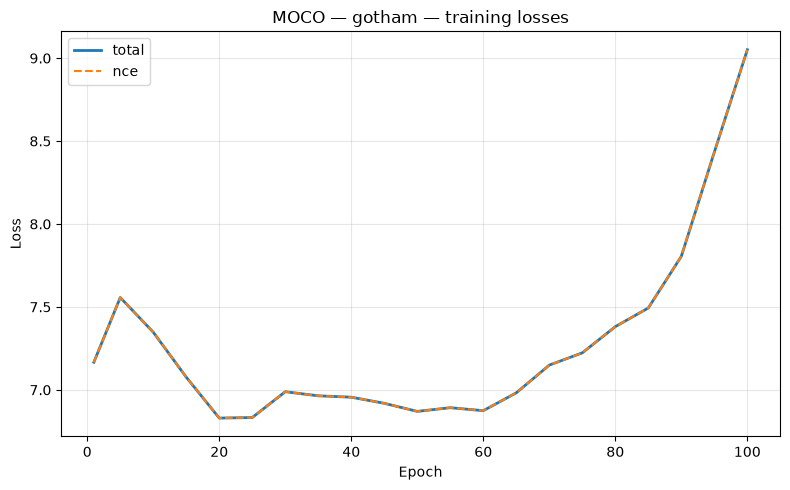

[plot] saved ssl_plots\MOCO\gotham\MOCO_gotham_losses.png


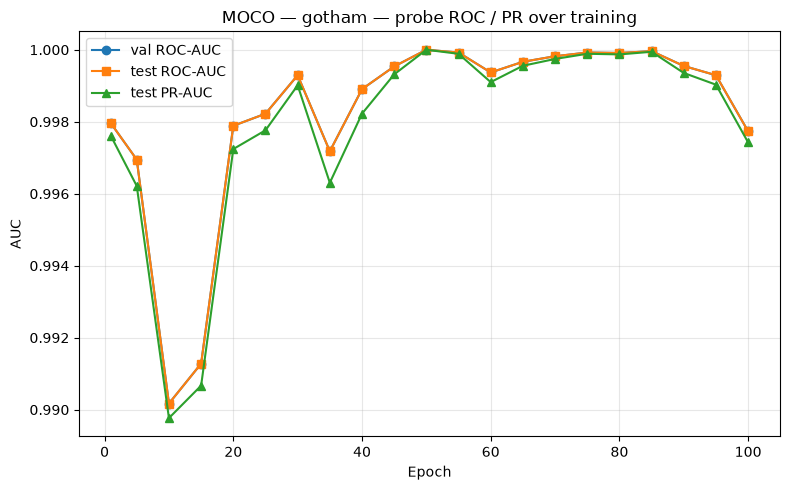

[plot] saved ssl_plots\MOCO\gotham\MOCO_gotham_probe_roc_pr.png


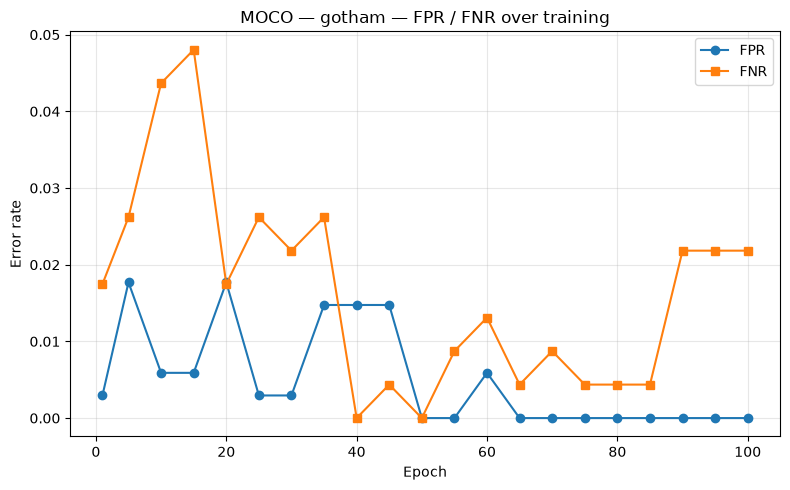

[plot] saved ssl_plots\MOCO\gotham\MOCO_gotham_probe_fpr_fnr.png


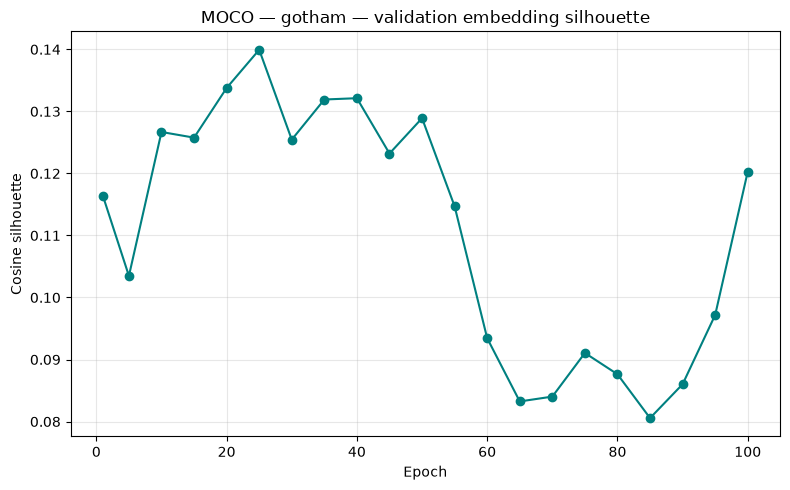

[plot] saved ssl_plots\MOCO\gotham\MOCO_gotham_probe_silhouette.png


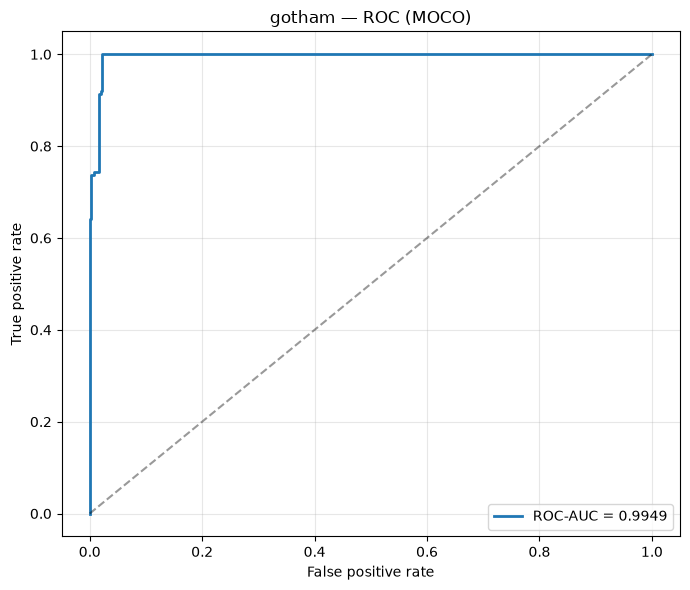

[plot] saved ssl_plots\MOCO\gotham\MOCO_gotham_roc.png


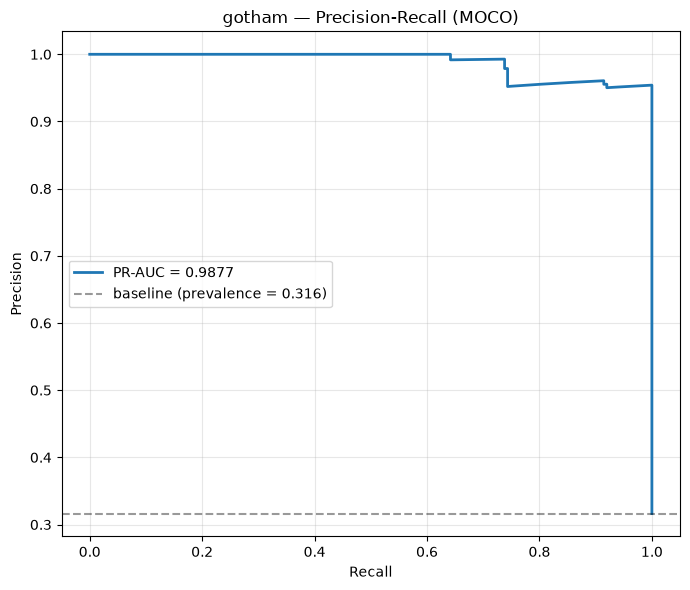

[plot] saved ssl_plots\MOCO\gotham\MOCO_gotham_pr.png


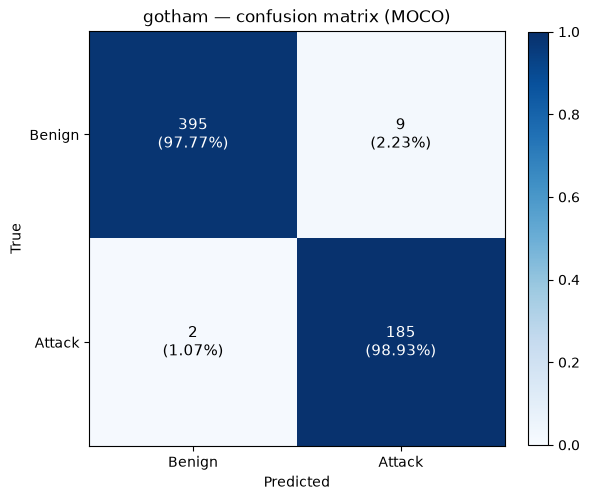

[plot] saved ssl_plots\MOCO\gotham\MOCO_gotham_confusion.png


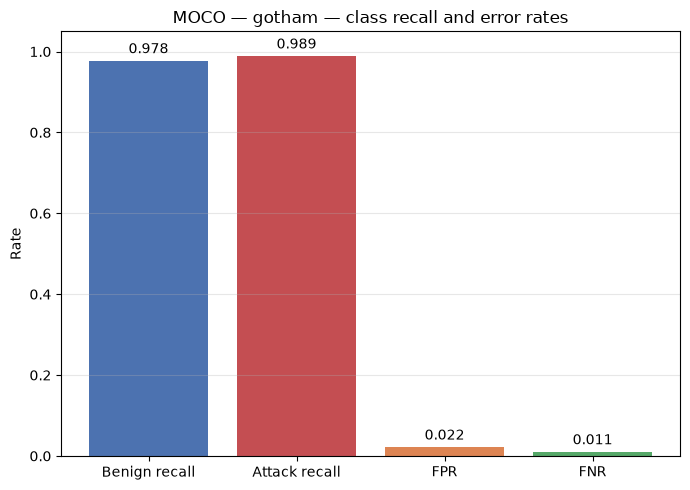

[plot] saved ssl_plots\MOCO\gotham\MOCO_gotham_class_rates.png
[plot] saved ssl_plots\MOCO\gotham\MOCO_gotham_classification_report.txt
[plot] gotham: embedding 832 graphs ...


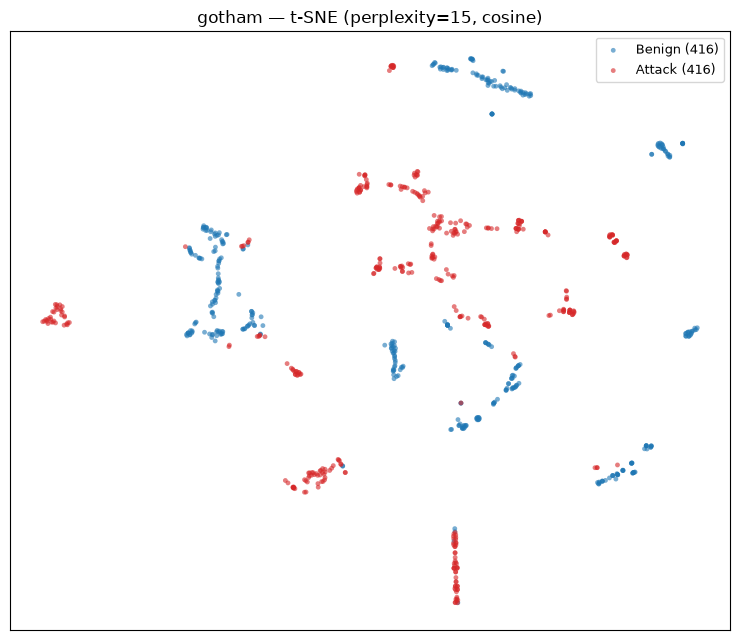

[plot] saved ssl_plots\MOCO\gotham\MOCO_gotham_tsne_binary.png


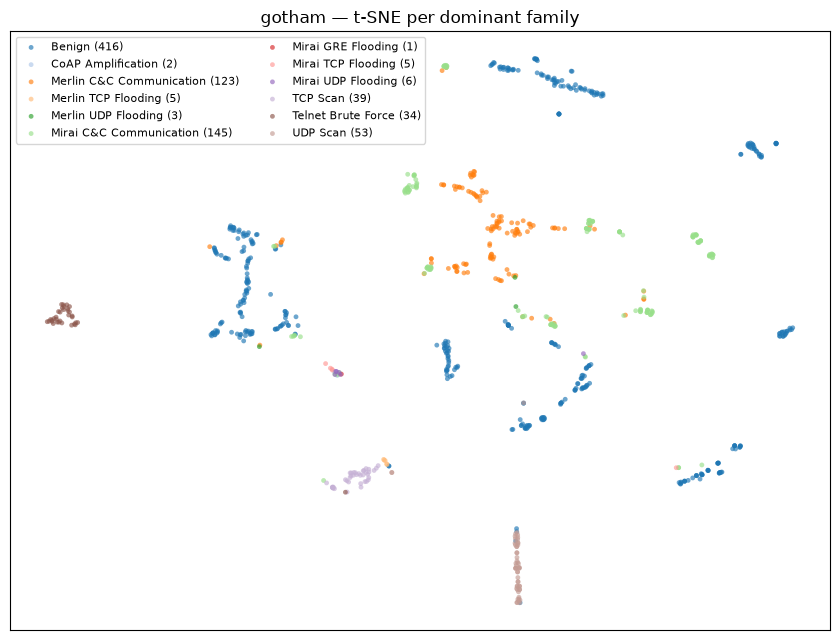

[plot] saved ssl_plots\MOCO\gotham\MOCO_gotham_tsne_family.png


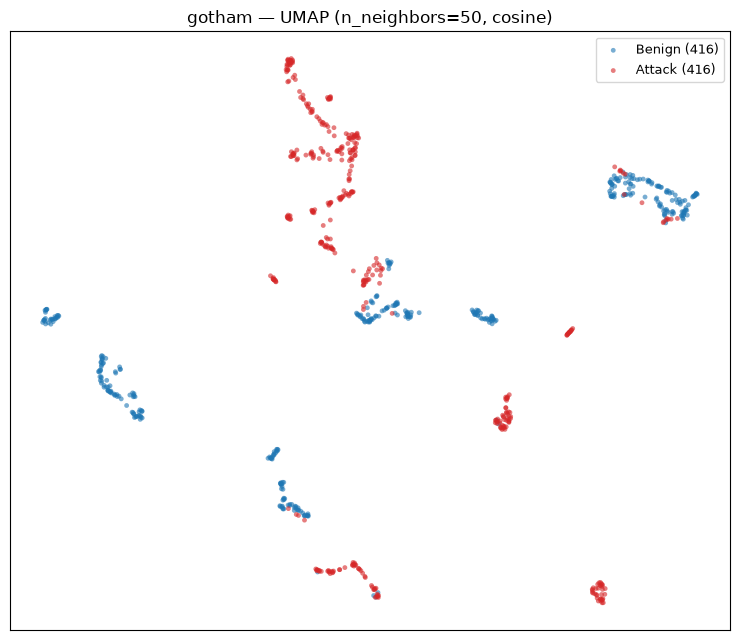

[plot] saved ssl_plots\MOCO\gotham\MOCO_gotham_umap_binary.png


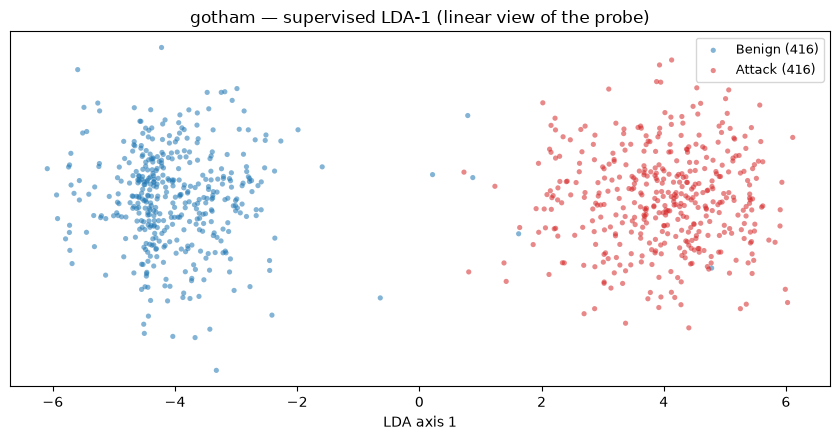

[plot] saved ssl_plots\MOCO\gotham\MOCO_gotham_lda.png
[cache] bundle 'nf_bot' already loaded

[plot] ==== MOCO · nf_bot ====


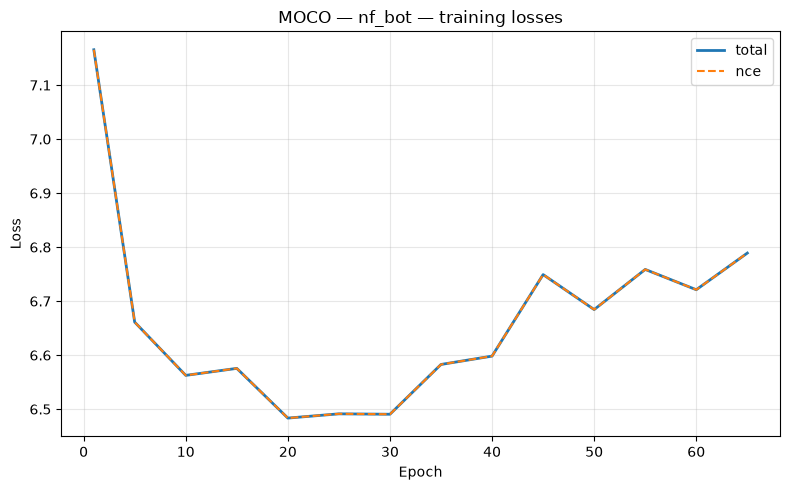

[plot] saved ssl_plots\MOCO\nf_bot\MOCO_nf_bot_losses.png


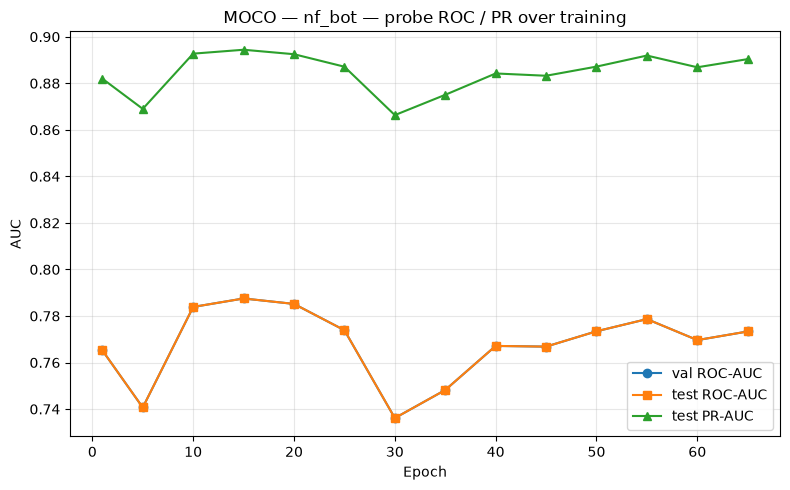

[plot] saved ssl_plots\MOCO\nf_bot\MOCO_nf_bot_probe_roc_pr.png


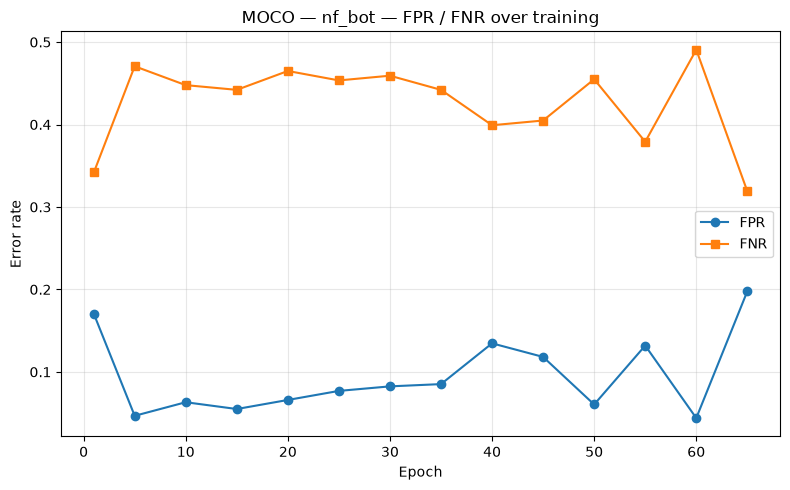

[plot] saved ssl_plots\MOCO\nf_bot\MOCO_nf_bot_probe_fpr_fnr.png


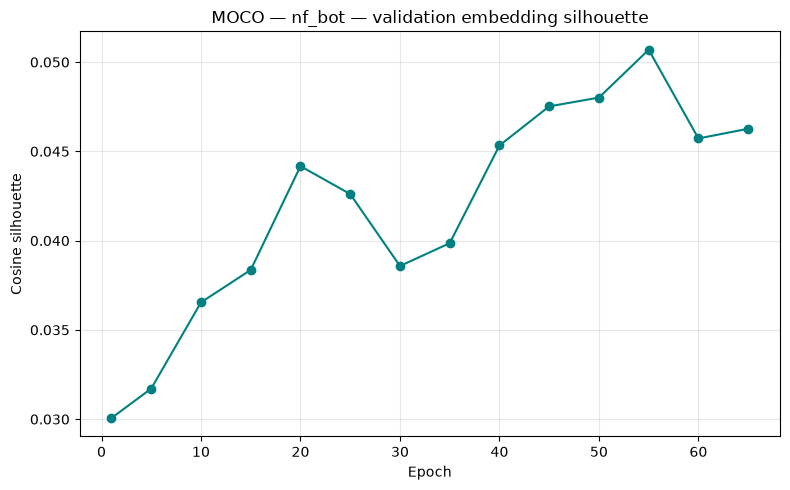

[plot] saved ssl_plots\MOCO\nf_bot\MOCO_nf_bot_probe_silhouette.png


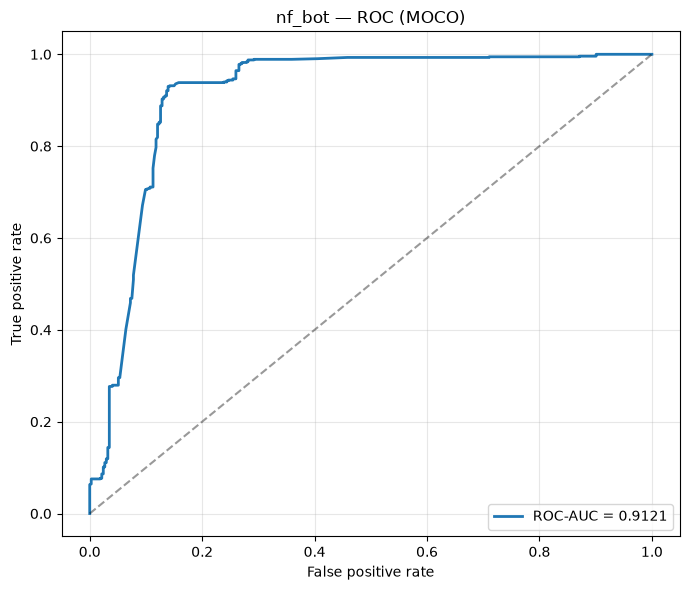

[plot] saved ssl_plots\MOCO\nf_bot\MOCO_nf_bot_roc.png


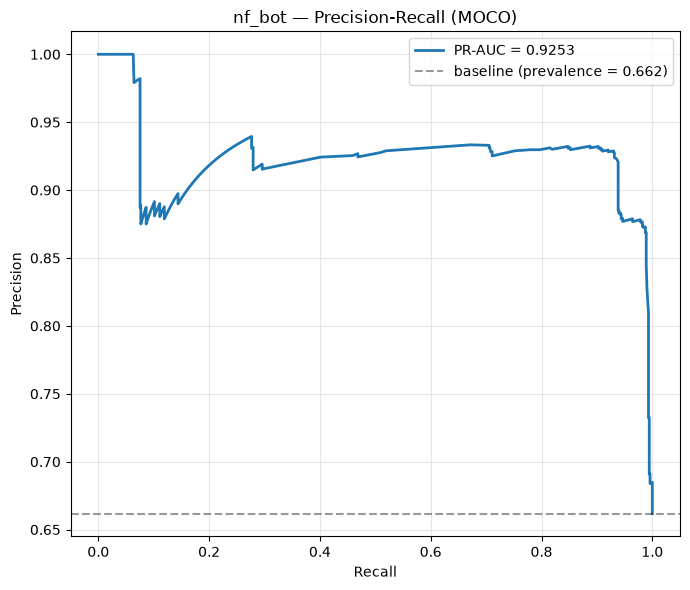

[plot] saved ssl_plots\MOCO\nf_bot\MOCO_nf_bot_pr.png


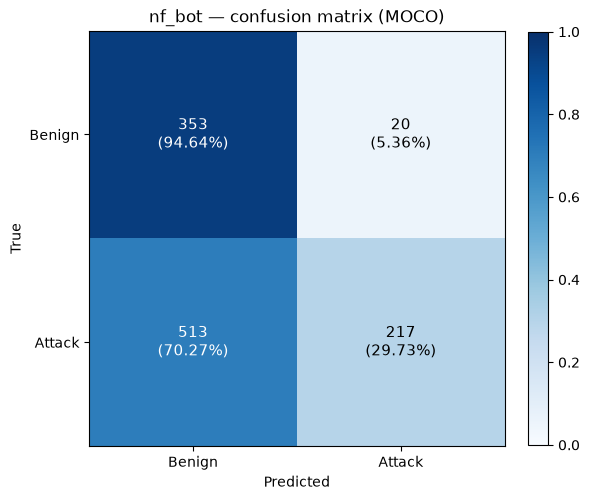

[plot] saved ssl_plots\MOCO\nf_bot\MOCO_nf_bot_confusion.png


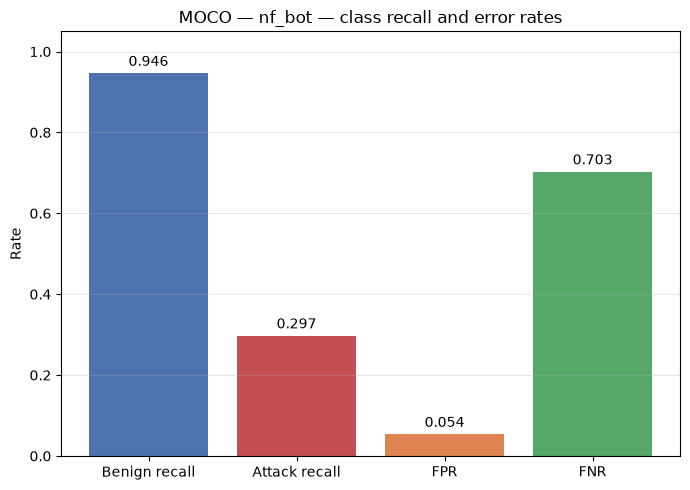

[plot] saved ssl_plots\MOCO\nf_bot\MOCO_nf_bot_class_rates.png
[plot] saved ssl_plots\MOCO\nf_bot\MOCO_nf_bot_classification_report.txt
[plot] nf_bot: embedding 1474 graphs ...


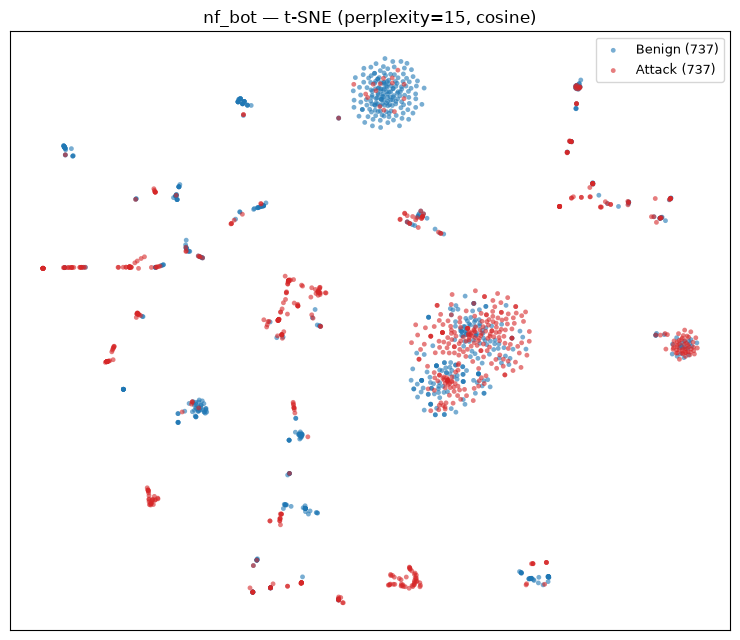

[plot] saved ssl_plots\MOCO\nf_bot\MOCO_nf_bot_tsne_binary.png


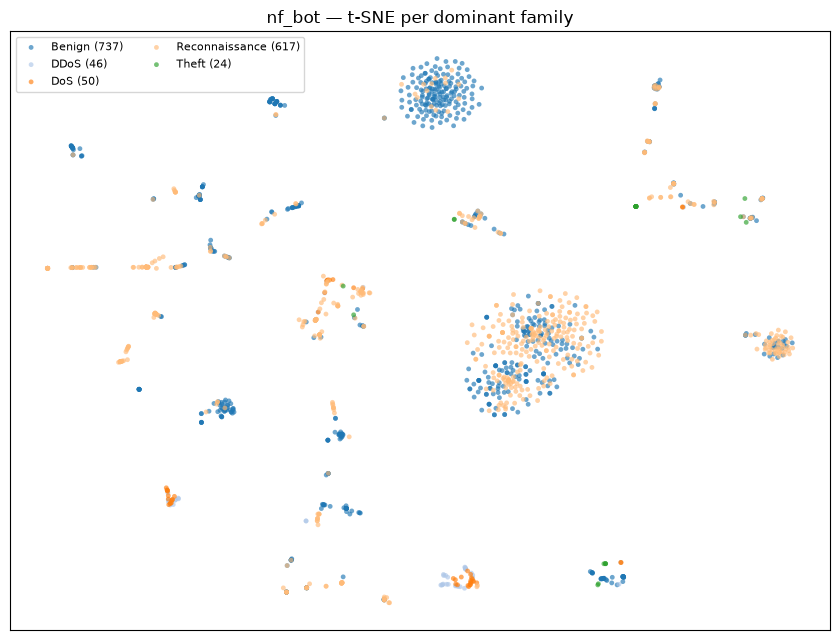

[plot] saved ssl_plots\MOCO\nf_bot\MOCO_nf_bot_tsne_family.png


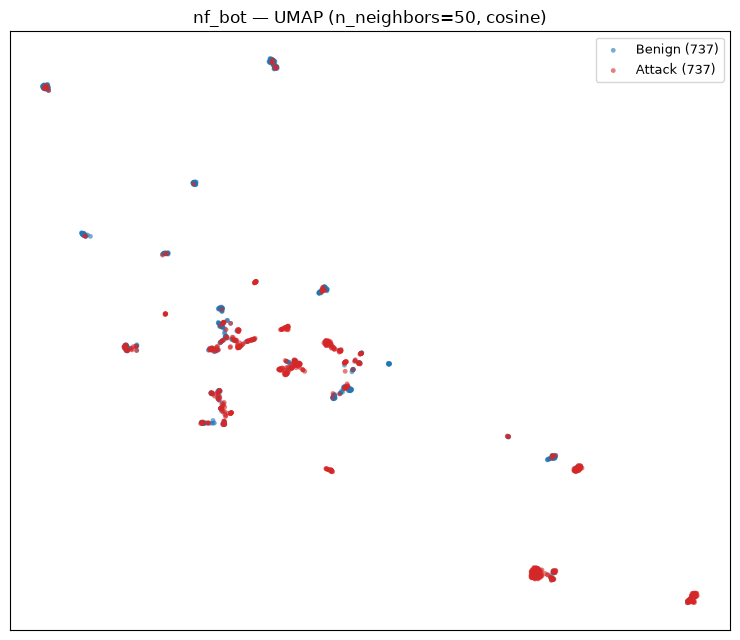

[plot] saved ssl_plots\MOCO\nf_bot\MOCO_nf_bot_umap_binary.png


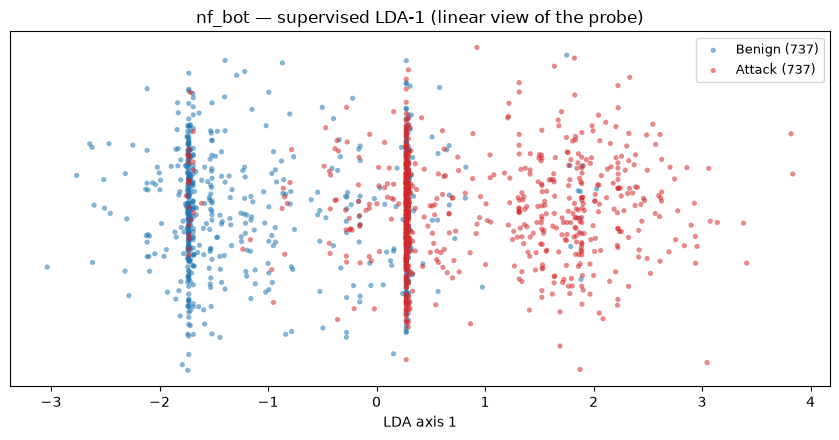

[plot] saved ssl_plots\MOCO\nf_bot\MOCO_nf_bot_lda.png
[cache] bundle 'nf_ton' already loaded

[plot] ==== MOCO · nf_ton ====


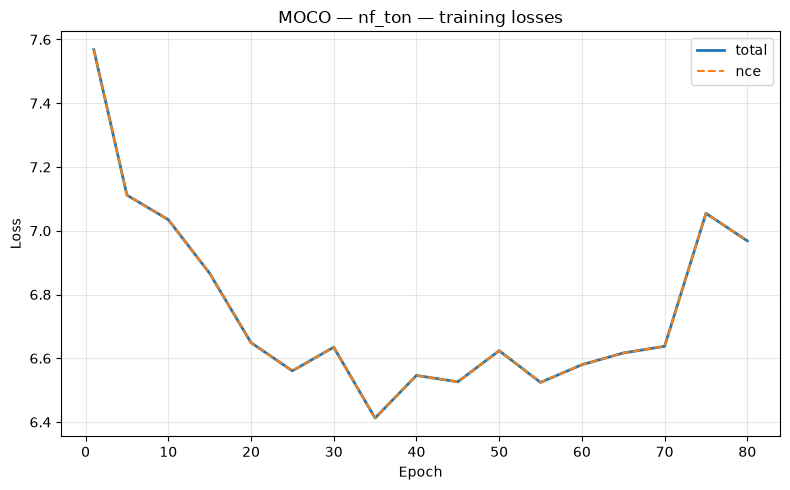

[plot] saved ssl_plots\MOCO\nf_ton\MOCO_nf_ton_losses.png


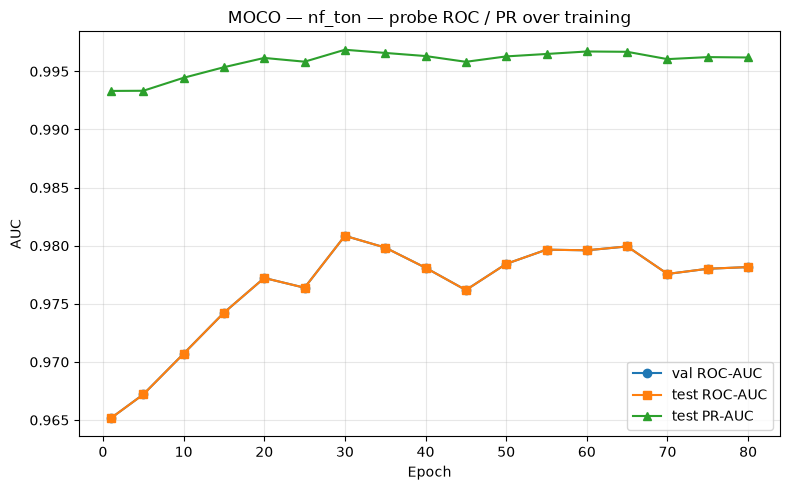

[plot] saved ssl_plots\MOCO\nf_ton\MOCO_nf_ton_probe_roc_pr.png


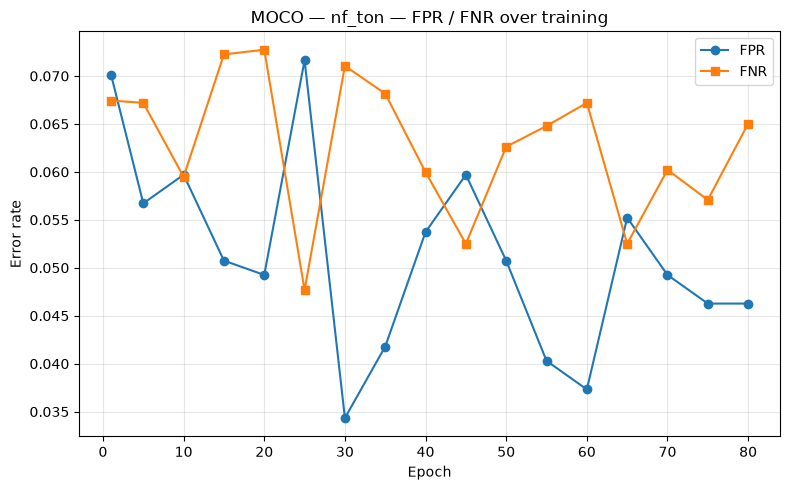

[plot] saved ssl_plots\MOCO\nf_ton\MOCO_nf_ton_probe_fpr_fnr.png


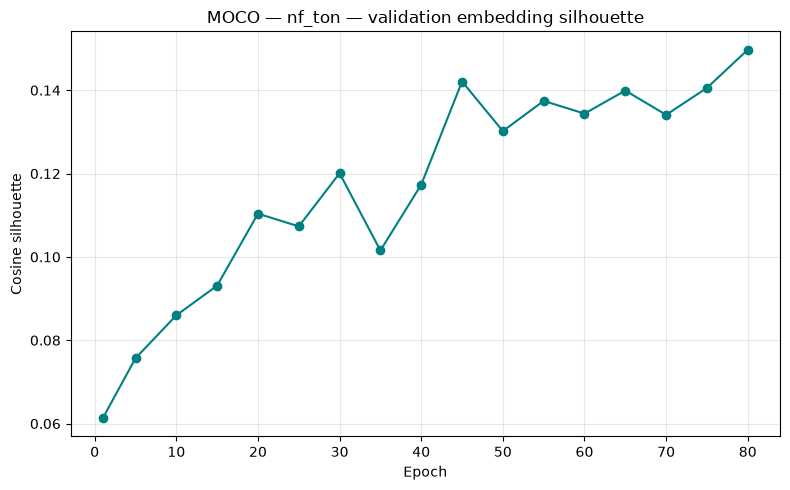

[plot] saved ssl_plots\MOCO\nf_ton\MOCO_nf_ton_probe_silhouette.png


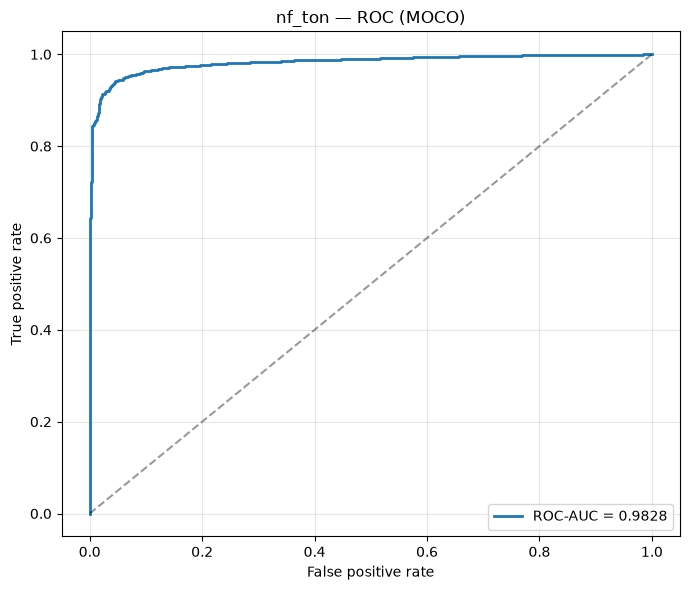

[plot] saved ssl_plots\MOCO\nf_ton\MOCO_nf_ton_roc.png


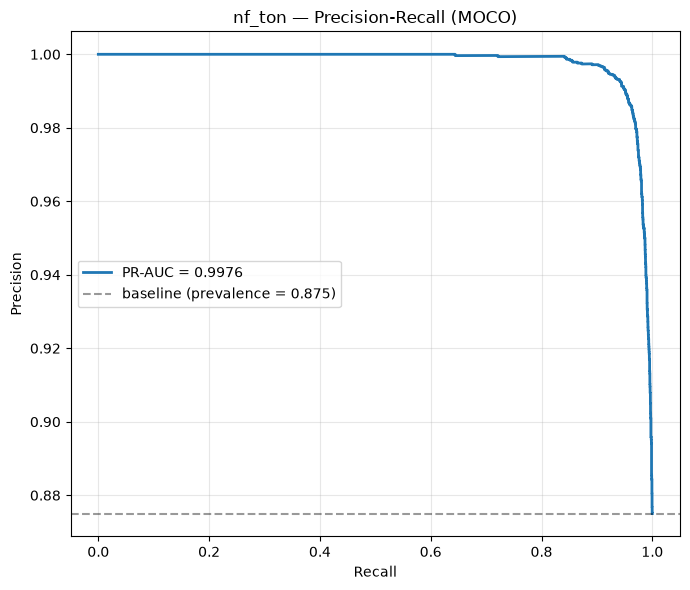

[plot] saved ssl_plots\MOCO\nf_ton\MOCO_nf_ton_pr.png


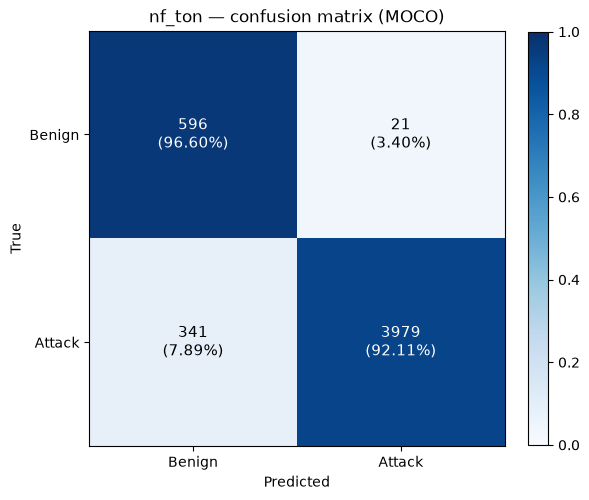

[plot] saved ssl_plots\MOCO\nf_ton\MOCO_nf_ton_confusion.png


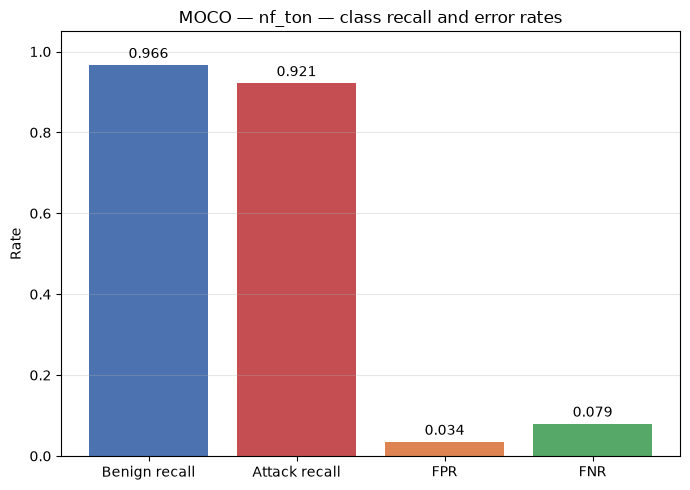

[plot] saved ssl_plots\MOCO\nf_ton\MOCO_nf_ton_class_rates.png
[plot] saved ssl_plots\MOCO\nf_ton\MOCO_nf_ton_classification_report.txt
[plot] nf_ton: embedding 2574 graphs ...


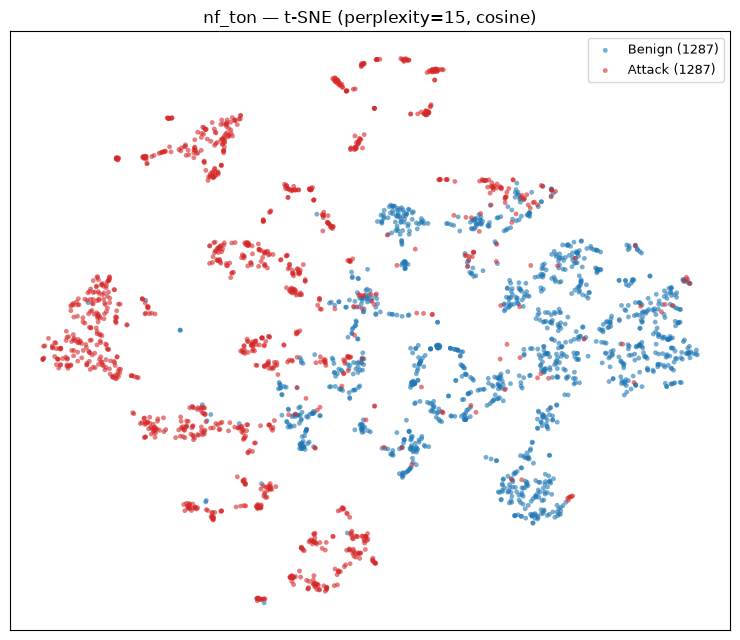

[plot] saved ssl_plots\MOCO\nf_ton\MOCO_nf_ton_tsne_binary.png


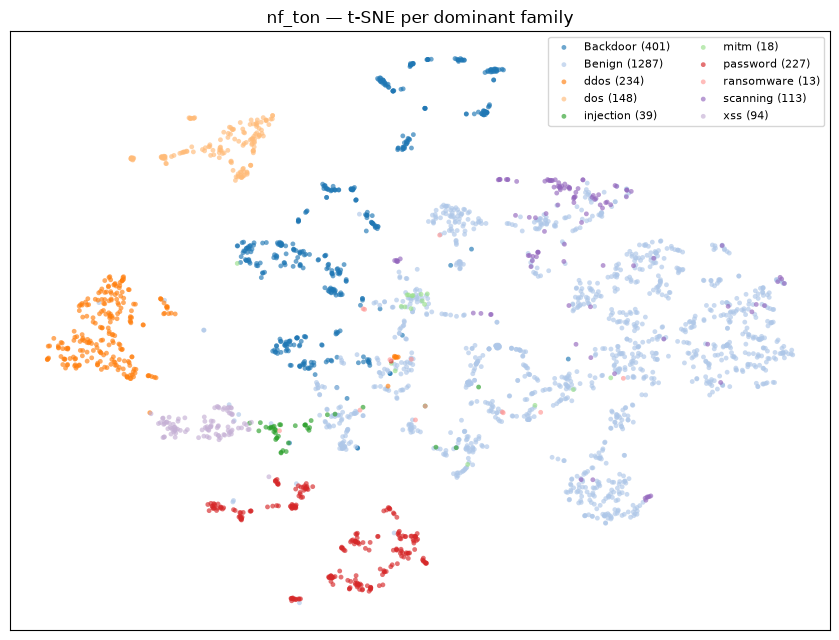

[plot] saved ssl_plots\MOCO\nf_ton\MOCO_nf_ton_tsne_family.png


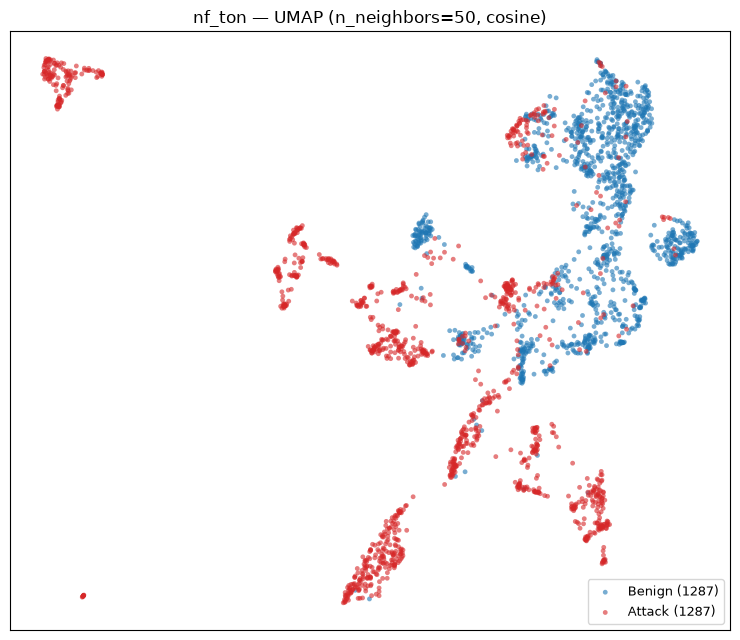

[plot] saved ssl_plots\MOCO\nf_ton\MOCO_nf_ton_umap_binary.png


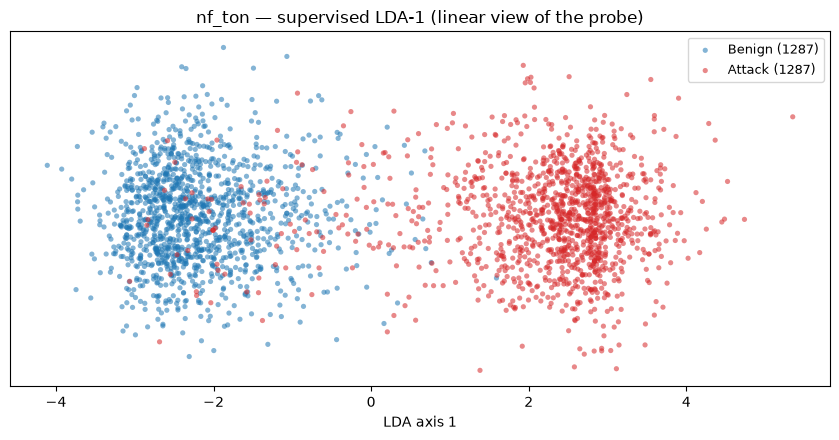

[plot] saved ssl_plots\MOCO\nf_ton\MOCO_nf_ton_lda.png


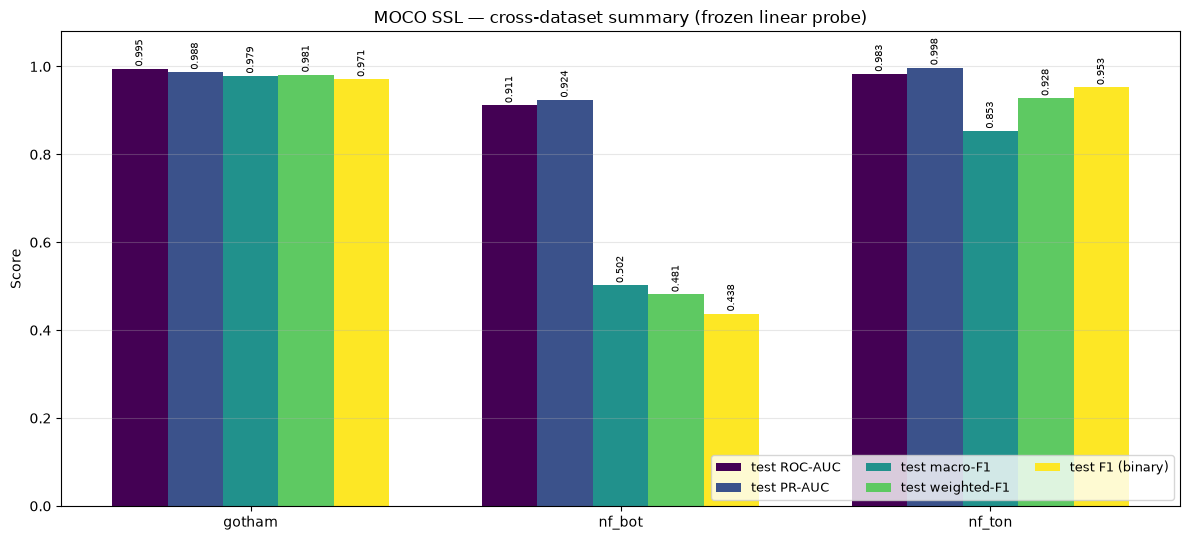

[plot] saved ssl_plots\MOCO\MOCO_cross_dataset_summary.png

[plot] done — everything under c:\Users\User\Desktop\MC-STGAT-IDS Experiment\MC-STGAT-IDS-V5\ssl_plots\MOCO/


In [17]:
import os, gc, json
import numpy as np
import matplotlib
%matplotlib inline
import matplotlib.pyplot as plt

from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import (roc_curve, precision_recall_curve,
                             confusion_matrix, classification_report,
                             average_precision_score, roc_auc_score,
                             f1_score)

try:
    from umap import UMAP
    HAS_UMAP = True
except Exception:
    HAS_UMAP = False
    print("[plot] umap-learn not installed — t-SNE only")

# ---------------------------------------------------------------
# METHOD auto-detect (BYOL or MoCo)
# ---------------------------------------------------------------
if 'byol_loss' in globals() or 'byol_momentum_schedule' in globals():
    METHOD = "BYOL"
elif ('info_nce_loss' in globals()
      or 'dequeue_and_enqueue' in globals()
      or 'MoCoModel' in globals()):
    METHOD = "MOCO"
else:
    raise RuntimeError("Cannot auto-detect METHOD — run the SSL notebook first.")

# ---------------------------------------------------------------
# Reuse whichever reports dict exists
# ---------------------------------------------------------------
if 'all_ssl_reports' in globals():
    _REPORTS = all_ssl_reports
elif 'ALL_SSL_REPORTS' in globals():
    _REPORTS = ALL_SSL_REPORTS
else:
    _REPORTS = {}

PLOT_ROOT = os.path.join("ssl_plots", METHOD)
os.makedirs(PLOT_ROOT, exist_ok=True)


def _plot_dir(dataset):
    p = os.path.join(PLOT_ROOT, dataset)
    os.makedirs(p, exist_ok=True)
    return p


def _nan_to_clean(X):
    return np.nan_to_num(X, nan=0.0, posinf=100.0, neginf=-100.0)


def _optimal_threshold(y_prob, y_true):
    """Youden's J — same as _youden_threshold, with a safe fallback."""
    try:
        return _youden_threshold(y_prob, y_true)
    except NameError:
        fpr, tpr, thr = roc_curve(y_true, y_prob)
        j = tpr - fpr
        return float(thr[np.argmax(j)]), None


def probe_with_predictions(X_train, y_train, X_val, y_val, X_test, y_test):
    Xtr_raw = _nan_to_clean(X_train)
    Xva_raw = _nan_to_clean(X_val)
    Xte_raw = _nan_to_clean(X_test)
    scaler  = StandardScaler().fit(Xtr_raw)
    Xtr = scaler.transform(Xtr_raw)
    Xva = scaler.transform(Xva_raw)
    Xte = scaler.transform(Xte_raw)
    if len(set(y_train)) < 2:
        return None
    lr = LogisticRegression(max_iter=3000, class_weight='balanced',
                            n_jobs=-1).fit(Xtr, y_train)
    pv = lr.predict_proba(Xva)[:, 1]
    pt = lr.predict_proba(Xte)[:, 1]
    thr, _ = _optimal_threshold(pv, y_val)
    return dict(prob_val=pv, prob_test=pt,
                y_val=y_val, y_test=y_test, thr=float(thr))


def load_trained_encoder(bundle):
    ckpt = torch.load(bundle['encoder_path'], map_location=DEVICE)
    enc = GATEncoder(ckpt['node_dim'], ckpt['hidden_dim'], ckpt['num_heads'],
                     ckpt['num_layers'], ckpt['edge_dim']).to(DEVICE)
    enc.load_state_dict(ckpt['encoder_state_dict'])
    enc.eval()
    return enc


def _save_fig(fig, path):
    plt.tight_layout()
    plt.savefig(path, dpi=140, bbox_inches='tight')
    plt.show()
    plt.close(fig)
    print(f"[plot] saved {path}")


# ---------------------------------------------------------------------
# SSL loss key candidates (per method)
# ---------------------------------------------------------------------
_SSL_LOSS_KEYS = {
    "BYOL": ['byol', 'byol_loss', 'ssl', 'ssl_loss'],
    "MOCO": ['moco', 'nce', 'infonce', 'info_nce',
             'contrastive', 'ssl', 'ssl_loss', 'loss_ssl'],
}


def _pick_ssl_key(history, method):
    """Return the first SSL-loss key actually present in the history."""
    if not history or not isinstance(history[0], dict):
        return None
    keys = history[0].keys()
    for k in _SSL_LOSS_KEYS.get(method, []):
        if k in keys:
            return k
    # last resort — anything that isn't a probe/metric/total key
    excluded = {'epoch', 'train_loss', 'loss', 'recon', 'momentum',
                'probe_val_roc', 'probe_test_roc', 'probe_test_pr',
                'probe_test_fpr', 'probe_test_fnr',
                'probe_val_silhouette'}
    for k in keys:
        if k not in excluded:
            return k
    return None


# ---------------------------------------------------------------------
# 1) Training curves — 4 separate figures
# ---------------------------------------------------------------------
def plot_training_curves(report, dataset, method):
    out_dir = _plot_dir(dataset)
    history = report.get('history', [])
    if not history:
        print(f"[plot] {dataset}: no history — skipping curves"); return

    ep = np.array([h.get('epoch', i) if isinstance(h, dict) else i
                   for i, h in enumerate(history)], dtype=float)

    def _arr(k):
        out = []
        for h in history:
            if isinstance(h, dict):
                v = h.get(k, None)
            else:
                v = None
            out.append(np.nan if v is None else float(v))
        return np.array(out, dtype=float)

    loss = _arr('train_loss')
    if np.all(np.isnan(loss)):
        loss = _arr('loss')

    ssl_key = _pick_ssl_key(history, method)
    ssl     = _arr(ssl_key) if ssl_key else np.full_like(ep, np.nan)
    rec     = _arr('recon')

    val_roc  = _arr('probe_val_roc')
    test_roc = _arr('probe_test_roc')
    test_pr  = _arr('probe_test_pr')
    test_fpr = _arr('probe_test_fpr')
    test_fnr = _arr('probe_test_fnr')
    sil      = _arr('probe_val_silhouette')

    # --- losses ---
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.plot(ep, loss, '-',  lw=2,   label='total')
    if ssl_key is not None and np.isfinite(ssl).any():
        ax.plot(ep, ssl, '--', lw=1.5, label=ssl_key)
    else:
        print(f"[plot] {dataset}: no SSL-loss column found — plotting total only")
    if np.isfinite(rec).any():
        ax.plot(ep, rec, ':', lw=1.5, label='recon')
    ax.set_xlabel("Epoch"); ax.set_ylabel("Loss")
    ax.set_title(f"{method} — {dataset} — training losses")
    ax.legend(); ax.grid(alpha=.3)
    _save_fig(fig, os.path.join(out_dir, f"{method}_{dataset}_losses.png"))

    # --- probe ROC / PR ---
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.plot(ep, val_roc,  'o-', label='val ROC-AUC')
    ax.plot(ep, test_roc, 's-', label='test ROC-AUC')
    ax.plot(ep, test_pr,  '^-', label='test PR-AUC')
    ax.set_xlabel("Epoch"); ax.set_ylabel("AUC")
    ax.set_title(f"{method} — {dataset} — probe ROC / PR over training")
    ax.legend(); ax.grid(alpha=.3)
    _save_fig(fig, os.path.join(out_dir, f"{method}_{dataset}_probe_roc_pr.png"))

    # --- FPR / FNR ---
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.plot(ep, test_fpr, 'o-', label='FPR')
    ax.plot(ep, test_fnr, 's-', label='FNR')
    ax.set_xlabel("Epoch"); ax.set_ylabel("Error rate")
    ax.set_title(f"{method} — {dataset} — FPR / FNR over training")
    ax.legend(); ax.grid(alpha=.3)
    _save_fig(fig, os.path.join(out_dir, f"{method}_{dataset}_probe_fpr_fnr.png"))

    # --- silhouette ---
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.plot(ep, sil, 'o-', color='teal')
    ax.set_xlabel("Epoch"); ax.set_ylabel("Cosine silhouette")
    ax.set_title(f"{method} — {dataset} — validation embedding silhouette")
    ax.grid(alpha=.3)
    _save_fig(fig, os.path.join(out_dir, f"{method}_{dataset}_probe_silhouette.png"))


# ---------------------------------------------------------------------
# 2) ROC and PR — separate figures
# ---------------------------------------------------------------------
def plot_roc_pr(encoder, bundle, dataset, method):
    out_dir = _plot_dir(dataset)
    X_train = embed_graphs(encoder, bundle['train_graphs'], DEVICE)
    X_val   = embed_graphs(encoder, bundle['val_graphs'],   DEVICE)
    X_test  = embed_graphs(encoder, bundle['test_graphs'],  DEVICE)

    p = probe_with_predictions(X_train, bundle['train_bin'],
                               X_val,   bundle['val_bin'],
                               X_test,  bundle['test_bin'])
    if p is None:
        print(f"[plot] {dataset}: single-class train — skipping ROC/PR"); return

    fpr, tpr, _ = roc_curve(p['y_test'], p['prob_test'])
    roc_auc     = roc_auc_score(p['y_test'], p['prob_test'])
    prec, rec, _ = precision_recall_curve(p['y_test'], p['prob_test'])
    pr_auc       = average_precision_score(p['y_test'], p['prob_test'])
    base         = p['y_test'].mean()

    fig, ax = plt.subplots(figsize=(7, 6))
    ax.plot(fpr, tpr, lw=2, label=f"ROC-AUC = {roc_auc:.4f}")
    ax.plot([0, 1], [0, 1], 'k--', alpha=.4)
    ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
    ax.set_title(f"{dataset} — ROC ({method})")
    ax.legend(); ax.grid(alpha=.3)
    _save_fig(fig, os.path.join(out_dir, f"{method}_{dataset}_roc.png"))

    fig, ax = plt.subplots(figsize=(7, 6))
    ax.plot(rec, prec, lw=2, label=f"PR-AUC = {pr_auc:.4f}")
    ax.axhline(base, color='k', ls='--', alpha=.4,
               label=f"baseline (prevalence = {base:.3f})")
    ax.set_xlabel("Recall"); ax.set_ylabel("Precision")
    ax.set_title(f"{dataset} — Precision-Recall ({method})")
    ax.legend(); ax.grid(alpha=.3)
    _save_fig(fig, os.path.join(out_dir, f"{method}_{dataset}_pr.png"))

    del X_train, X_val, X_test
    gc.collect()
    if DEVICE.type == 'cuda': torch.cuda.empty_cache()


# ---------------------------------------------------------------------
# 3) Confusion matrix and class-rate bar
# ---------------------------------------------------------------------
def plot_confusion_and_class_report(encoder, bundle, dataset, method):
    out_dir = _plot_dir(dataset)
    X_train = embed_graphs(encoder, bundle['train_graphs'], DEVICE)
    X_val   = embed_graphs(encoder, bundle['val_graphs'],   DEVICE)
    X_test  = embed_graphs(encoder, bundle['test_graphs'],  DEVICE)

    p = probe_with_predictions(X_train, bundle['train_bin'],
                               X_val,   bundle['val_bin'],
                               X_test,  bundle['test_bin'])
    if p is None:
        print(f"[plot] {dataset}: single-class train — skipping confusion"); return

    y_true = p['y_test']
    y_pred = (p['prob_test'] >= p['thr']).astype(int)

    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    recall_benign = cm[0, 0] / max(cm[0].sum(), 1)
    recall_attack = cm[1, 1] / max(cm[1].sum(), 1)
    fpr           = cm[0, 1] / max(cm[0].sum(), 1)
    fnr           = cm[1, 0] / max(cm[1].sum(), 1)

    fig, ax = plt.subplots(figsize=(6, 5.5))
    cmn = cm / cm.sum(1, keepdims=True).clip(min=1)
    im = ax.imshow(cmn, cmap='Blues', vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i,j]}\n({cmn[i,j]:.2%})",
                    ha='center', va='center',
                    color='white' if cmn[i, j] > 0.5 else 'black',
                    fontsize=11)
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    ax.set_xticklabels(['Benign', 'Attack'])
    ax.set_yticklabels(['Benign', 'Attack'])
    ax.set_xlabel("Predicted"); ax.set_ylabel("True")
    ax.set_title(f"{dataset} — confusion matrix ({method})")
    plt.colorbar(im, ax=ax, fraction=0.045)
    _save_fig(fig, os.path.join(out_dir, f"{method}_{dataset}_confusion.png"))

    fig, ax = plt.subplots(figsize=(7, 5))
    labels = ['Benign recall', 'Attack recall', 'FPR', 'FNR']
    values = [recall_benign, recall_attack, fpr, fnr]
    colors = ['#4C72B0', '#C44E52', '#DD8452', '#55A868']
    bars = ax.bar(labels, values, color=colors)
    for b, v in zip(bars, values):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.01, f"{v:.3f}",
                ha='center', va='bottom', fontsize=10)
    ax.set_ylim(0, 1.05)
    ax.set_ylabel("Rate")
    ax.set_title(f"{method} — {dataset} — class recall and error rates")
    ax.grid(alpha=.3, axis='y')
    _save_fig(fig, os.path.join(out_dir, f"{method}_{dataset}_class_rates.png"))

    rep = classification_report(y_true, y_pred,
                                target_names=['Benign', 'Attack'],
                                digits=4, zero_division=0)
    txt_path = os.path.join(out_dir,
                            f"{method}_{dataset}_classification_report.txt")
    with open(txt_path, 'w') as f:
        f.write(f"{method} — {dataset} — test set\n")
        f.write(f"threshold = {p['thr']:.4f}\n\n{rep}")
    print(f"[plot] saved {txt_path}")

    del X_train, X_val, X_test
    gc.collect()
    if DEVICE.type == 'cuda': torch.cuda.empty_cache()


# ---------------------------------------------------------------------
# 4) Embeddings — cosine-aligned
# ---------------------------------------------------------------------
def plot_embeddings(encoder, bundle, dataset, method,
                    max_points=3000, seed=None):
    if seed is None:
        seed = globals().get('SEED', 0)
    out_dir = _plot_dir(dataset)
    rng = np.random.default_rng(seed)

    val_g  = bundle['val_graphs'];   val_y  = bundle['val_bin']
    test_g = bundle['test_graphs'];  test_y = bundle['test_bin']

    def _balanced_idx(y, k):
        idx0 = np.where(y == 0)[0]; idx1 = np.where(y == 1)[0]
        k_half = min(k // 2, len(idx0), len(idx1))
        if k_half == 0:
            k_half = min(k, max(len(idx0), len(idx1)))
        s0 = rng.choice(idx0, min(k_half, len(idx0)), replace=False)
        s1 = rng.choice(idx1, min(k_half, len(idx1)), replace=False)
        return np.concatenate([s0, s1])

    idx_v = _balanced_idx(val_y,  max_points // 2)
    idx_t = _balanced_idx(test_y, max_points // 2)

    sub_val  = [val_g[i]  for i in idx_v];  y_val_sub  = val_y[idx_v]
    sub_test = [test_g[i] for i in idx_t];  y_test_sub = test_y[idx_t]

    _thr = bundle.get('attack_threshold', None)

    def _fam(g):
        try:
            if _thr is None:
                return 'Benign'
            return dominant_family(g, _thr)
        except Exception:
            return 'Benign'

    fam_val  = np.array([_fam(g) for g in sub_val])
    fam_test = np.array([_fam(g) for g in sub_test])

    print(f"[plot] {dataset}: embedding {len(sub_val) + len(sub_test)} graphs ...")
    X_val_e  = embed_graphs(encoder, sub_val,  DEVICE)
    X_test_e = embed_graphs(encoder, sub_test, DEVICE)
    X_raw = np.vstack([X_val_e, X_test_e])
    y_bin = np.concatenate([y_val_sub,  y_test_sub])
    y_fam = np.concatenate([fam_val,    fam_test])

    X = X_raw / np.clip(np.linalg.norm(X_raw, axis=1, keepdims=True), 1e-8, None)
    n_pca = min(30, X.shape[1] - 1, X.shape[0] - 1)
    Xp = PCA(n_components=n_pca, random_state=seed).fit_transform(X)
    Xp = Xp / np.clip(np.linalg.norm(Xp, axis=1, keepdims=True), 1e-8, None)

    perp = min(15, max(5, (len(Xp) - 1) // 3))

    # --- Fig 1: t-SNE binary ---
    tsne = TSNE(n_components=2, perplexity=perp, init='pca',
                learning_rate='auto', metric='cosine',
                random_state=seed).fit_transform(Xp)
    fig, ax = plt.subplots(figsize=(7.5, 6.5))
    for c, lbl, col in [(0, 'Benign', '#1f77b4'), (1, 'Attack', '#d62728')]:
        m = y_bin == c
        ax.scatter(tsne[m, 0], tsne[m, 1], s=12, c=col, alpha=0.6,
                   label=f"{lbl} ({m.sum()})", edgecolors='none')
    ax.set_title(f"{dataset} — t-SNE (perplexity={perp}, cosine)")
    ax.legend(fontsize=9); ax.set_xticks([]); ax.set_yticks([])
    _save_fig(fig, os.path.join(out_dir, f"{method}_{dataset}_tsne_binary.png"))

    # --- Fig 2: t-SNE per family ---
    fig, ax = plt.subplots(figsize=(8.5, 6.5))
    uniq = sorted(set(y_fam))
    cmap = plt.get_cmap('tab20')
    fam_colors = {f: cmap(i % 20) for i, f in enumerate(uniq)}
    for f in uniq:
        m = y_fam == f
        ax.scatter(tsne[m, 0], tsne[m, 1], s=12,
                   color=fam_colors[f], alpha=0.65,
                   label=f"{f} ({m.sum()})", edgecolors='none')
    ax.set_title(f"{dataset} — t-SNE per dominant family")
    ax.legend(fontsize=8, loc='best', ncol=2)
    ax.set_xticks([]); ax.set_yticks([])
    _save_fig(fig, os.path.join(out_dir, f"{method}_{dataset}_tsne_family.png"))

    # --- Fig 3: UMAP binary ---
    if HAS_UMAP:
        try:
            umap2d = UMAP(n_components=2, n_neighbors=50, min_dist=0.3,
                          metric='cosine',
                          random_state=seed).fit_transform(Xp)
            fig, ax = plt.subplots(figsize=(7.5, 6.5))
            for c, lbl, col in [(0, 'Benign', '#1f77b4'), (1, 'Attack', '#d62728')]:
                m = y_bin == c
                ax.scatter(umap2d[m, 0], umap2d[m, 1], s=12, c=col,
                           alpha=0.6, label=f"{lbl} ({m.sum()})",
                           edgecolors='none')
            ax.set_title(f"{dataset} — UMAP (n_neighbors=50, cosine)")
            ax.legend(fontsize=9); ax.set_xticks([]); ax.set_yticks([])
            _save_fig(fig, os.path.join(out_dir, f"{method}_{dataset}_umap_binary.png"))
        except Exception as e:
            print(f"[plot] UMAP failed ({e}); skipping UMAP panel")

    # --- Fig 4: supervised LDA-1 ---
    if len(set(y_bin)) == 2:
        try:
            Xs2  = StandardScaler().fit_transform(X)
            lda1 = LinearDiscriminantAnalysis(n_components=1)\
                     .fit_transform(Xs2, y_bin)
            jitter = rng.normal(0, 0.02, size=(len(lda1), 1))
            lda2d  = np.hstack([lda1, jitter])
            fig, ax = plt.subplots(figsize=(8.5, 4.5))
            for c, lbl, col in [(0, 'Benign', '#1f77b4'), (1, 'Attack', '#d62728')]:
                m = y_bin == c
                ax.scatter(lda2d[m, 0], lda2d[m, 1], s=14, c=col, alpha=0.55,
                           label=f"{lbl} ({m.sum()})", edgecolors='none')
            ax.set_title(f"{dataset} — supervised LDA-1 (linear view of the probe)")
            ax.set_yticks([]); ax.set_xlabel("LDA axis 1")
            ax.legend(fontsize=9)
            _save_fig(fig, os.path.join(out_dir, f"{method}_{dataset}_lda.png"))
        except Exception as e:
            print(f"[plot] LDA failed ({e}); skipping LDA panel")

    del X, Xp, X_raw, tsne, X_val_e, X_test_e
    gc.collect()
    if DEVICE.type == 'cuda': torch.cuda.empty_cache()


# ---------------------------------------------------------------------
# 5) Cross-dataset summary  (tolerant to key-name differences)
# ---------------------------------------------------------------------
def plot_cross_dataset_summary(all_reports, method):
    datasets = [d for d, r in all_reports.items()
                if isinstance(r, dict) and 'error' not in r]
    if not datasets:
        print("[plot] no reports to summarise"); return

    # each entry: (list-of-candidate-keys, display-name)
    metrics = [
        (['test_roc_auc', 'test_auc', 'roc_auc', 'test_AUC'], 'test ROC-AUC'),
        (['test_pr_auc',  'test_ap',  'pr_auc',  'test_AP'],  'test PR-AUC'),
        (['test_macro_f1', 'test_f1_macro', 'macro_f1'],      'test macro-F1'),
        (['test_weighted_f1', 'test_f1_weighted', 'weighted_f1'], 'test weighted-F1'),
        (['test_f1_binary', 'test_f1', 'f1_binary'],          'test F1 (binary)'),
    ]

    def _first_val(report, keys):
        for k in keys:
            if k in report:
                try:
                    return float(report[k])
                except (TypeError, ValueError):
                    return np.nan
        return np.nan

    x = np.arange(len(datasets)); w = 0.15
    fig, ax = plt.subplots(figsize=(12, 5.5))
    cmap = plt.get_cmap('viridis')
    for i, (keys, name) in enumerate(metrics):
        vals = [_first_val(all_reports[d], keys) for d in datasets]
        bars = ax.bar(x + (i - len(metrics) / 2 + 0.5) * w,
                      vals, width=w, label=name,
                      color=cmap(i / max(len(metrics) - 1, 1)))
        for b, v in zip(bars, vals):
            if np.isfinite(v):
                ax.text(b.get_x() + b.get_width() / 2, v + 0.005,
                        f"{v:.3f}", ha='center', va='bottom',
                        fontsize=7, rotation=90)
    ax.set_xticks(x); ax.set_xticklabels(datasets)
    ax.set_ylim(0, 1.08); ax.set_ylabel("Score")
    ax.set_title(f"{method} SSL — cross-dataset summary (frozen linear probe)")
    ax.legend(loc='lower right', ncol=3, fontsize=9)
    ax.grid(alpha=.3, axis='y')
    _save_fig(fig, os.path.join(PLOT_ROOT, f"{method}_cross_dataset_summary.png"))


# ---------------------------------------------------------------------
# 6) Driver — runs the same block for BYOL and MoCo
# ---------------------------------------------------------------------
print(f"\n[plot] METHOD auto-detected = {METHOD}")
print(f"[plot] outputs  >  {os.path.abspath(PLOT_ROOT)}/\n")

_DATASETS = globals().get('DATASETS_TO_RUN', ['gotham', 'nf_bot', 'nf_ton'])

for _ds in _DATASETS:
    bundle = load_dataset_bundle(_ds)
    if not os.path.isfile(bundle['encoder_path']):
        print(f"[plot] {_ds}: no encoder checkpoint — skipping"); continue

    print(f"\n[plot] ==== {METHOD} · {_ds} ====")
    enc = load_trained_encoder(bundle)

    try:
        _rep = _REPORTS.get(_ds) if isinstance(_REPORTS, dict) else None
        if _rep is None and os.path.isfile(bundle.get('report_path', '')):
            with open(bundle['report_path']) as f:
                _rep = json.load(f)
        if _rep is not None and 'error' not in _rep:
            plot_training_curves(_rep, _ds, METHOD)

        plot_roc_pr(enc, bundle, _ds, METHOD)
        plot_confusion_and_class_report(enc, bundle, _ds, METHOD)
        plot_embeddings(enc, bundle, _ds, METHOD, max_points=3000)
    except Exception as e:
        import traceback; traceback.print_exc()
        print(f"[plot] {_ds} failed: {e}")

    del enc
    gc.collect()
    if DEVICE.type == 'cuda': torch.cuda.empty_cache()

if _REPORTS:
    plot_cross_dataset_summary(_REPORTS, METHOD)
else:
    print("[plot] no all_ssl_reports / ALL_SSL_REPORTS — skipping cross-dataset summary")

print(f"\n[plot] done — everything under {os.path.abspath(PLOT_ROOT)}/")